# Coupled ABM: FloodAdapt and DYNAMO-M, full analysis

This is the complete run set: every scenario (R1 to R8, including the clipped-hazard comparison), all three income tiers, the verification paths and the background appendices. For a shorter entry point with the main steps only, start with [2_coupled_abm_walkthrough.ipynb](2_coupled_abm_walkthrough.ipynb).

## 1. Introduction and context

### 1.1 Context and aim of the coupling project

The FloodAdapt-ABM coupling project integrates the physical flood risk modelling of FloodAdapt (using SFINCS and FIAT) with the behavioural agent-based modelling of DYNAMO-M. The goal is to provide a comprehensive framework to assess how household-level adaptation decisions (like floodproofing) evolve dynamically alongside rising sea levels and stochastic flood events over time.

### 1.2 Aim of this notebook

This notebook serves as the runner for simulating adaptation. It demonstrates how to initialize the simulation engine, configure the Subjective Expected Utility (SEU) decision rules, run the simulation, and visualize the adaptation outcomes over a multi-decade horizon.

### 1.3 What falls under minimum viable product (MVP)

The MVP bridges the core SEU decision kernel from DYNAMO-M. Agents perceive risk from recent floods, compute expected utility, and are held to an affordability limit. On top of that the coupling adds flood insurance as a third option, a Poisson hazard draw, severity-scaled risk perception, a synthetic income model, and the household income workflow in Section 2.6.

Migration, regional economic feedbacks and the government dike agent are out of scope.

Full scope list and what is deliberately excluded: [Appendix B.1](#app-b1).


### 1.4 Why a lightweight `AgentState` instead of full DYNAMO-M

Full DYNAMO-M parses gigabytes of geospatial data and builds a memory-heavy object per building. This engine instead keeps plain NumPy arrays and reads only what the SEU maths needs from the lookup table. Runs take seconds instead of hours, and stay bit-for-bit identical to native.

How that identity is guaranteed: [Appendix B.2](#app-b2).


### 1.5 One engine, clearly-labelled roles

This repository has exactly **one** compute kernel, `SimulationEngine.step`, and several *drivers* that own the clock around it. Their roles:

| Entry point | Role | Use it for |
|---|---|---|
| `run_mesa_native_full` | **MAIN engine**: the real honeybees `Model` (native DYNAMO-M framework) owns the clock | All application runs (this notebook) |
| `engine.run(n_jobs=...)` | Compute kernel + parallel Monte-Carlo backend | Verification & experiments |
| `run_mesa_native` | Framework-free mirror of the native tick loop | The tick-driver bit-parity gate (verification) |
| `ABMSimulator` | Deprecated standalone threshold simulator | Backward compatibility only |

The intermediate drivers exist because the coupling was built as a **step-wise verification ladder** (kernel, then framework-free mirror, then native honeybees integration), each step gated by bit-for-bit parity so the coupled version provably never drifted from the validated science. They are retained as verification gates, not as alternative models.

### 1.6 Documentation guide: what to read next?

The repository keeps two core documents with distinct roles, plus one method guide:

1. **`docs/architecture.md`**, the **design record**: *why and how the system is built*. Coupling architecture, the SEU decision science for adaptation and insurance, severity-response formulations, deviations from native DYNAMO-M (Appendix B).
2. **`floodadapt_abm_documentation.md`**, the **reference manual**: *how to use the package*. Every module, class, function and configuration field, with examples.
3. **`docs/calibration_validation_guide.md`**, the **method guide**: how to calibrate and validate the behavioural parameters.

`README.md` (root) is the front door: quick-start, installation, pipeline overview.

## 2. Workflow setup

This section covers the common initialization steps required before running the simulation: environment setup, helper functions, the core architecture, Monte-Carlo sequences for uncertainty, and the scenario configuration.

### 2.1 Setup

We start by importing the necessary packages and loading a pre-computed lookup table generated by Stage 1 (`setup_lookup_table.py`). 
This NetCDF file (`.nc`) contains matrices for inundation depth and economic damage per building, sea-level-rise (SLR) scenario, strategy, and event. This pre-computation removes the need to run heavy physical models (SFINCS or FIAT) during the agent simulation, making it exceptionally fast.

In [13]:
import sys, os, platform
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# Make floodadapt_abm importable and reuse the examples' dataset loader.
_REPO = Path.cwd()
if _REPO.name == "notebooks":
    _REPO = _REPO.parent
sys.path.insert(0, str(_REPO))
sys.path.insert(0, str(_REPO / "examples_engine"))

from _shared import load_dataset  # noqa: E402

import floodadapt_abm as fabm
from floodadapt_abm import (
    SimulationEngine, CouplingConfig, DecisionConfig,
    SEURule, ThresholdRule, DynamoLiveRule,
    preferred_decision_rule,
    run_mesa_native, run_mesa_native_full,
    DYNAMO_M_AVAILABLE, HONEYBEES_AVAILABLE,
)
# Post-processing and figures (Section 2.2): pure functions over the
# results dict; the notebook calls plt.show() itself.
from floodadapt_abm import analysis, plotting

print("Python           :", platform.python_version())
print("numpy / xarray   :", np.__version__, "/", xr.__version__)
print("honeybees present:", HONEYBEES_AVAILABLE, " (real Mesa/honeybees run path)")
print("DYNAMO-M present :", DYNAMO_M_AVAILABLE, " (native DecisionModule parity)")

Python           : 3.11.14
numpy / xarray   : 1.26.4 / 2025.11.0
honeybees present: True  (real Mesa/honeybees run path)
DYNAMO-M present : True  (native DecisionModule parity)


### 2.2 Helper functions: `analysis` and `plotting`

Post-processing and figures are package modules, so this notebook, the example scripts and batch runs share one implementation:

* `floodadapt_abm.analysis` turns the results dict into per-year aggregates and tables: `damage_per_year`, `avoided_damage_per_year`, `cumulative_uptake`, `create_summary_table`, `scenario_summary`, and the insurance affordability diagnostics.
* `floodadapt_abm.plotting` draws the figures used below and returns `Figure` objects; the notebook calls `plt.show()`.

**Two views of uptake.** `adoption_fraction` and `insured_fraction` are per-year *stocks*: the share of households holding the status in that year. Floodproofing persists for `lifespan_dryproof` years (75, longer than this horizon), so its stock only rises. Insurance is a one-year contract re-decided every year, so its stock rises and falls with premiums and affordability. For a comparable view, `analysis.cumulative_uptake` gives the share that has *ever* taken the action by year *t*. The insurance figures show the two in separate panels (ever insured, currently insured), one line per scenario; floodproofing panels show a single line per run because the two coincide while `lifespan_dryproof` exceeds the horizon. The tables report both.

In [14]:
# The helpers used below live in the package and were imported in Section 2.1:
#   floodadapt_abm.analysis  - per-year aggregates, summary tables, affordability
#   floodadapt_abm.plotting  - the figures (each returns a Figure)
print("analysis :", ", ".join(n for n in analysis.__dict__
                              if not n.startswith("_") and callable(analysis.__dict__[n])))
print("plotting :", ", ".join(n for n in plotting.__dict__
                              if n.startswith(("plot_", "overlay_"))))

analysis : money_unit, has_insurance, current_uptake, cumulative_uptake, count_history, uptake_statistics, damage_per_year, cumulative_damage, avoided_damage_per_year, cumulative_avoided_damage, household_cost_per_year, cumulative_household_cost, mean_and_std, create_summary_table, scenario_summary, premium_offers, ead_summary, affordability_table, affordability_vs_subsidy
plotting : overlay_slr, plot_band, plot_uptake, plot_adaptation_overview, plot_rule_hazard_comparison, plot_insurance_overview, plot_subsidy_experiment, plot_affordability_curve


### 2.3 The coupled architecture, concisely

The simulation is built around three main components:
1. **Kernel**: The core computational function (`SimulationEngine.step`) that performs the numeric work every simulated year.
2. **Decision Rule**: A pluggable logic module that governs household behaviour (e.g., whether to adopt floodproofing).
3. **Clock Owner**: The outer loop that advances time.

Because the different execution methods (paths) share the exact same kernel and the same sequence of random numbers (Random Number Generator stream), they produce bit-for-bit identical results. This ensures reproducibility whether you run the full native model or the lightweight mirror.

| Piece | Responsibility | Provided by |
|---|---|---|
| **Lookup table** | Flood damage per building / SLR / event / strategy | **FloodAdapt** |
| **`LookupTableAdapter`** | Maps table data to agent arrays; interpolates at each SLR | This repo |
| **`SimulationEngine.step`** | The single per-year kernel (events, damage, state updates) | This repo |
| **Decision rule** | Logic to adapt or not each year (SEU / native / threshold) | DYNAMO-M science, pluggable |
| **Clock owner** | Advances the year loop | Execution methods |

### 2.4 Monte-Carlo sequences and multiprocessing

**Sequences.** Flood events are *stochastic* (random): each year, each event either happens or not based on its probability. A single run represents just one possible "weather history". To capture uncertainty, we run **several independent sequences** with different random streams and report the **mean ± spread** (standard deviation).

**Multiprocessing.** Because sequences are independent, they can be run in parallel. `engine.run(..., n_jobs=N)` distributes the sequences across multiple processor cores. The parallel result is **bit-identical** to the sequential one. It just finishes much faster.

### 2.5 Configuration

The `DecisionConfig` defaults are:

- **Poisson hazard draw** (`event_draw_mode="poisson"`, no discard cap). Event frequencies are occurrence *rates*, so every event's realised long-run rate matches its nominal frequency. Rare extremes are never crowded out by frequent nuisance events. In plain terms: the Poisson distribution answers "how many times does something with a known average rate happen this year", so nothing needs to be clipped or thrown away.
- **Exceedance SEU probabilities** (`seu_prob_mode="exceedance"`, `p = 1 − e^(−freq)`).
- **Severity-scaled risk perception** (`perception_mode="severity"`). A nuisance flood and a catastrophe no longer look identical to the agent. The post-flood perception spike scales as $s^\gamma$. Here $s$ is the **damage severity**: the realised damage divided by the building's maximum potential damage, clipped to $[0, 1]$. So $s = 0.25$ means the flood destroyed a quarter of what the home could lose. The exponent $\gamma$ = `perception_severity_exponent` (default 0.5) is the **single** shape parameter: below 1 it is concave, at 1 linear, above 1 it discounts small floods (the near-miss hypothesis).

  **The default is an assumption, not data.** $\gamma = 0.5$ is argued from the availability heuristic and is not calibrated for Charleston. It matters here: on the real table, sweeping $\gamma$ from 0.25 to 3 moves final adoption by a factor of three and cumulative damage by 50 %. Treat it like `rank_correlation` in [C.3](#app-c3): sweep it (0.25 / 0.5 / 1.0 / 2.0), or fit it from a small survey. Both recipes and the measured sweep figures are in `docs/calibration_validation_guide.md`; the design rationale is in `docs/architecture.md` ("Severity response").
- **Synthetic lognormal incomes** (`income_mode="synthetic_lognormal"`, native DYNAMO-M port). Income is independent of building value, so the affordability constraint genuinely binds. Section 2.6 shows how the percentiles are assigned for this case study.

For the **real Charleston table** we additionally set `nuisance_freq_threshold = 1.0`. Its probabilistic event set contains ~11 sub-annual (`freq > 1`) events whose near-certain probabilities would otherwise collapse onto the 0.998 perceived-probability cap inside the SEU integral. Dropping them is also the long-standing convention for this event set.

In [15]:
# --- Scenario ---------------------------------------------------------------
START_YEAR = 2020
N_YEARS    = 30
NO_SEQ     = 5          # Monte-Carlo sequences
SEED       = 42

# --- Dataset Selection: Synthetic vs. Real Charleston Table ----------------
# OPTION 1: Run on the fast SYNTHETIC table (runs in seconds)
# USE_REAL_TABLE = False

# OPTION 2: Run on the real 2GB CHARLESTON table (takes several minutes)
USE_REAL_TABLE = True

# OPTION 3: Control via environment variable (useful for CI/automated runs)
# USE_REAL_TABLE = os.environ.get("FA_ABM_REAL_TABLE", "0").lower() in ("1", "true", "yes")

ds, source = load_dataset(prefer_real=USE_REAL_TABLE)
print(f"Lookup table : {source}")
print(f"dimensions   : {dict(ds.sizes)}")

# --- Decision / coupling configuration --------------------------------------
# Current defaults: Poisson hazard draw, exceedance SEU probabilities,
# severity-scaled perception, synthetic lognormal incomes.
# Every switch also accepts an alternative setting; Section 4.3 uses
# them to build the R2 and R3 comparison runs.
config = CouplingConfig(random_seed=SEED)
if "real" in source:
    # Recommended for the Charleston probabilistic set: drop sub-annual
    # nuisance events (freq > 1/yr) from the catalogue (see Section 2.5).
    config.decision.nuisance_freq_threshold = 1.0

# Household income percentiles are assigned in Section 2.6 below.

# --- SLR trajectory (the driver) --------------------------------------------
# Preferred, if a FloodAdapt database is available:
#   import flood_adapt.api as fa
#   slr_values = np.array([fa.interp_slr(slr_scenario="NOAA High", year=START_YEAR+t)
#                          for t in range(N_YEARS)])

# Fallback: a linear ramp across the lookup table's SLR grid.
slr_values = np.linspace(float(ds.slr.min()), float(ds.slr.max()), N_YEARS)
years = START_YEAR + np.arange(N_YEARS)
print(f"SLR trajectory: {slr_values[0]:.2f} -> {slr_values[-1]:.2f} "
      f"({ds.slr.attrs.get('units', 'table units')}) over {N_YEARS} years")

Lookup table : real Charleston table (lookup_table_charleston_beta_release_ABM_probabilistic_set.nc)
dimensions   : {'object_id': 61858, 'slr': 5, 'strategy': 2, 'event': 207}
SLR trajectory: 0.00 -> 2.00 (table units) over 30 years


### 2.6 Assigning household incomes

Every household needs an income. The engine uses it for the affordability check: a household may not spend more than `expenditure_cap` of its income on floodproofing or on a premium. Income is set in two steps, and the two steps need different data.

| Step | What it fixes | Set by | Needs building locations? |
|---|---|---|---|
| 1. The income distribution | how much a household at percentile *p* earns | `median_income`, `mean_median_inc_ratio` | **No.** It describes the whole county |
| 2. The percentile per building | which *building* sits at percentile *p* | `income_percentile_per_agent` | **Yes**, unless you assume a proxy |

A percentile of 80 means the household earns more than 80 % of households in the region. This mirrors native DYNAMO-M.

**What this notebook runs for Charleston:**

* **Step 1 is calibrated to real data.** ACS gives Charleston County a median household income of $88,494 and a mean/median ratio of 1.4879. Both are measured, not assumed.
* **Step 2 uses the building-value proxy, not a spatial join.** The lookup table carries no coordinates, so census income cannot be linked to a building here. The percentile follows the building value rank with a target correlation of 0.5, plus noise. That is an assumption, and it is flagged as one.

The next two cells do this. The first defines the Tier A and Tier B helpers, which need building footprints. They are defined but not called, because no FloodAdapt database is available here. The second cell runs Tier C and checks the fitted distribution against a census histogram it never used to fit.

One practical note: supplying percentiles changes what the income random stream draws, so numbers shift against an older uniform-fallback run at the same seed. That is expected, not a regression.

Background and sources, all in [Appendix C](#app-c):
[why a lognormal and what the two numbers do](#app-c1) |
[the three tiers for step 2](#app-c2) |
[where the ACS numbers come from](#app-c3) |
[how calibration and validation are kept apart](#app-c4) |
[worked example, percentile to income to wealth](#app-c5) |
[the wealth-to-income table](#app-c6)


In [16]:
# --- Tier A / Tier B: income data joined by location (runs when available) ---
# This cell only LOADS a percentile file if a previous run produced one.
# The two helpers below show how to actually build one. They are defined but
# not called: both need network access, a Census API key and geopandas.
#
# The key is free. Request one at https://api.census.gov/data/key_signup.html
# (organisation name + email, arrives by email in a few minutes). It is read
# from the CENSUS_API_KEY environment variable so it never appears in this
# notebook or in git. Set it once per machine:
#     PowerShell:  setx CENSUS_API_KEY "your-key-here"   (then open a new shell)
#     bash:        export CENSUS_API_KEY=your-key-here
#
# TIGER/Line shapefiles are large (about 16 MB per state layer), so they are
# cached outside the repository. Override the location with FA_ABM_CENSUS_CACHE.
import os
import tempfile

CENSUS_CACHE = Path(
    os.environ.get(
        "FA_ABM_CENSUS_CACHE",
        Path(tempfile.gettempdir()) / "floodadapt_abm_census",
    )
)


def _census_api_key(api_key=None):
    """Resolve the Census API key from the argument or the environment.

    Raises a directed error rather than letting an unauthenticated request
    fail later with a confusing parse error.
    """
    key = api_key or os.environ.get("CENSUS_API_KEY")
    if not key:
        raise RuntimeError(
            "No Census API key found. Request a free one at "
            "https://api.census.gov/data/key_signup.html, then set the "
            "CENSUS_API_KEY environment variable "
            '(PowerShell: setx CENSUS_API_KEY "your-key-here").'
        )
    return key


def _census_get_json(url):
    """GET a Census Data API URL and return the parsed JSON payload.

    The API answers a missing or invalid key with HTTP 200 and an HTML
    "Missing Key" page, so a plain json.load raises a misleading
    JSONDecodeError pointing at line 1 column 1. Detect that case and say
    what is actually wrong.
    """
    import json as _json
    import urllib.request

    with urllib.request.urlopen(url, timeout=120) as resp:
        content_type = resp.headers.get("Content-Type", "")
        body = resp.read()
    head = body[:200].lstrip().lower()
    if ("html" in content_type.lower()
            or head.startswith(b"<html")
            or head.startswith(b"<!doctype")):
        raise RuntimeError(
            "The Census API returned an HTML page instead of data. This "
            "means the API key is missing or invalid: the API answers with "
            "HTTP 200 and a 'Missing Key' page rather than an error status. "
            "Request a free key at "
            "https://api.census.gov/data/key_signup.html and set "
            "CENSUS_API_KEY."
        )
    return _json.loads(body)


def _download_tiger(url, dest_dir):
    """Download and extract a TIGER/Line shapefile once, then reuse it.

    Returns the directory holding the extracted shapefile, which geopandas
    can read directly.
    """
    import io
    import urllib.request
    import zipfile

    dest_dir = Path(dest_dir)
    if any(dest_dir.glob("*.shp")):          # already downloaded earlier
        return dest_dir
    dest_dir.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(url, timeout=300) as resp:
        buf = io.BytesIO(resp.read())
    zipfile.ZipFile(buf).extractall(dest_dir)
    return dest_dir


def fetch_acs_block_group_income(state_fips, county_fips, api_key=None,
                                 year=2024, cache_dir=None):
    """Download ACS median household income per block group as a GeoDataFrame.

    The return value is the `regions_gdf` that `derive_income_percentiles`
    expects: one polygon per block group, carrying an income column.

    Two public sources are combined:
      1. the values, from the Census Data API (table B19013, 5-year ACS).
         A free key is required, read from CENSUS_API_KEY if not passed.
      2. the geometries, from TIGER/Line shapefiles (no key needed).
    They are joined on GEOID, the code identifying a block group.

    Charleston County, SC is state_fips="45", county_fips="019".
    """
    import geopandas as gpd
    import pandas as pd

    key = _census_api_key(api_key)
    cache = Path(cache_dir) if cache_dir is not None else CENSUS_CACHE

    # 1. values: one row per block group; B19013_001E = median household income
    api = (f"https://api.census.gov/data/{year}/acs/acs5"
           f"?get=NAME,B19013_001E&for=block%20group:*"
           f"&in=state:{state_fips}%20county:{county_fips}&key={key}")
    rows = _census_get_json(api)
    inc = pd.DataFrame(rows[1:], columns=rows[0])
    # GEOID = state(2) + county(3) + tract(6) + block group(1) = 12 digits
    inc["GEOID"] = (inc["state"] + inc["county"]
                    + inc["tract"] + inc["block group"])
    inc["median_hh_income"] = pd.to_numeric(inc["B19013_001E"], errors="coerce")
    # ACS marks suppressed estimates with negative sentinels (e.g. -666666666).
    inc.loc[inc["median_hh_income"] < 0, "median_hh_income"] = float("nan")

    # 2. geometries: statewide block groups, filtered to the county
    tiger = (f"https://www2.census.gov/geo/tiger/TIGER{year}/BG/"
             f"tl_{year}_{state_fips}_bg.zip")
    shp_dir = _download_tiger(tiger, cache / f"tiger_bg_{year}_{state_fips}")
    gdf = gpd.read_file(shp_dir)
    gdf = gdf[gdf["COUNTYFP"] == county_fips]

    # 3. values onto geometries -> this is regions_gdf
    return gdf.merge(inc[["GEOID", "median_hh_income"]], on="GEOID", how="left")


def fetch_tract_income(state_fips, county_fips, api_key=None,
                       year=2024, cache_dir=None):
    """Tier B fallback: the same join one level coarser, at tract level.

    Use when block-group estimates are too noisy or unpublished. A tract holds
    about 1,200 to 8,000 people; a block group about 600 to 3,000.

    Outside the US, replace this with any polygon layer carrying an income or
    GDP-per-capita column: Global Data Lab subnational areas
    (globaldatalab.org), or a WorldPop wealth grid dissolved to admin units.
    Nothing else changes: any GeoDataFrame with an income column is a valid
    regions_gdf.
    """
    import geopandas as gpd
    import pandas as pd

    key = _census_api_key(api_key)
    cache = Path(cache_dir) if cache_dir is not None else CENSUS_CACHE

    api = (f"https://api.census.gov/data/{year}/acs/acs5"
           f"?get=NAME,B19013_001E&for=tract:*"
           f"&in=state:{state_fips}%20county:{county_fips}&key={key}")
    rows = _census_get_json(api)
    inc = pd.DataFrame(rows[1:], columns=rows[0])
    inc["GEOID"] = inc["state"] + inc["county"] + inc["tract"]
    inc["median_hh_income"] = pd.to_numeric(inc["B19013_001E"], errors="coerce")
    inc.loc[inc["median_hh_income"] < 0, "median_hh_income"] = float("nan")

    tiger = (f"https://www2.census.gov/geo/tiger/TIGER{year}/TRACT/"
             f"tl_{year}_{state_fips}_tract.zip")
    shp_dir = _download_tiger(tiger, cache / f"tiger_tract_{year}_{state_fips}")
    gdf = gpd.read_file(shp_dir)
    gdf = gdf[gdf["COUNTYFP"] == county_fips]
    return gdf.merge(inc[["GEOID", "median_hh_income"]], on="GEOID", how="left")


# --- The full Tier A workflow, end to end -----------------------------------
# Run once, with a Census API key and a FloodAdapt database at hand:
#
#   import flood_adapt.api as fa
#   from floodadapt_abm.income_utils import derive_income_percentiles
#
#   # (a) regions_gdf: the income polygons (function above). The key comes
#   #     from CENSUS_API_KEY, so nothing secret is written down here.
#   regions_gdf = fetch_acs_block_group_income("45", "019")
#
#   # (b) buildings: footprints keyed by Object ID, from the FloodAdapt
#   #     database (needs the [pipeline] extra). The lookup .nc carries no
#   #     coordinates, so the geometry has to come from here.
#   buildings = fa.get_building_footprint_impacts(scenario_name)  # GeoDataFrame
#
#   # (c) align buildings to this table's residential agent order
#   types = np.asarray(ds["object_id"].attrs["primary_object_type"], dtype=str)
#   res_mask = np.char.find(types, "RES") >= 0
#   buildings_res = buildings.set_index("Object ID").reindex(
#       np.asarray(ds["object_id"].values)[res_mask])
#
#   # (d) spatial join + percentiles, then cache for later runs
#   pct = derive_income_percentiles(buildings_res, regions_gdf,
#                                   income_column="median_hh_income")
#   np.save("income_percentiles_charleston.npy", pct)
#
# Tier B is identical except for step (a): swap in fetch_tract_income(...),
# or any other polygon layer with an income column.

_pct_file = Path("income_percentiles_charleston.npy")
income_percentiles = np.load(_pct_file) if _pct_file.exists() else None
print("Tier A/B percentile file:",
      f"loaded ({_pct_file})" if income_percentiles is not None else "not found")

Tier A/B percentile file: not found


In [17]:
# --- Tier C: county income statistics + building-value proxy (runs here) -----
from floodadapt_abm.income_utils import (
    ACS_B19001_LABELS,
    bracket_fit_distance,
    fetch_acs_county_income,
    fetch_acs_income_brackets,
    lognormal_bracket_shares,
    percentiles_from_value_proxy,
)

# === Axis 1: the regional income distribution (needs NO building locations) ==
# SOURCE: US Census Bureau, American Community Survey, 2020-2024 5-year
# estimates (the latest release; 2025 is not published yet), Charleston
# County, South Carolina (state FIPS 45, county FIPS 019). Fetched with
# income_utils.fetch_acs_county_income("45", "019", year=2024)
# and pinned below so this notebook reproduces offline.
#
# Machine-readable (what fetch_acs_county_income calls), reproduce with:
#   https://api.census.gov/data/2024/acs/acs5?get=NAME,B19013_001E,B19025_001E,B11001_001E&for=county:019&in=state:45&key=YOUR_KEY
# Human-browsable, no key needed, to eyeball the same tables:
#   https://data.census.gov/table/ACSDT5Y2024.B19013?g=050XX00US45019   (median)
#   https://data.census.gov/table/ACSDT5Y2024.B19025?g=050XX00US45019  (aggregate)
#   https://data.census.gov/table/ACSDT5Y2024.B11001?g=050XX00US45019  (households)
#   https://data.census.gov/profile/Charleston_County,_South_Carolina?g=050XX00US45019
#
#   B19013_001E  median household income      $88,494
#   B19025_001E  aggregate household income   $23,566,353,400
#   B11001_001E  households                   178,975
#   mean = aggregate / households              $131,674
#
# Pinned as constants so this notebook reproduces offline and the figures stay
# stable. Set CENSUS_API_KEY to re-fetch and check them against the live API
# (the cell below reports any drift rather than silently using new numbers).
# ACS_YEAR is passed to every fetch below so the pinned figures and the live
# check can never silently refer to different vintages.
ACS_YEAR = 2024
ACS_MEDIAN_HH_INCOME = 88_494.0
ACS_MEAN_HH_INCOME   = 131_674.0

config.decision.median_income = ACS_MEDIAN_HH_INCOME
config.decision.mean_median_inc_ratio = ACS_MEAN_HH_INCOME / ACS_MEDIAN_HH_INCOME

_have_key = bool(os.environ.get("CENSUS_API_KEY"))
if _have_key:
    _live = fetch_acs_county_income("45", "019", year=ACS_YEAR)
    _drift = abs(_live["mean_income"] - ACS_MEAN_HH_INCOME) / ACS_MEAN_HH_INCOME
    print(f"ACS live check    : median ${_live['median_income']:,.0f}, "
          f"mean ${_live['mean_income']:,.0f} over "
          f"{_live['n_households']:,.0f} households "
          f"(pinned mean differs by {_drift * 100:.4f} %)")
else:
    print("ACS live check    : skipped, no CENSUS_API_KEY set; using pinned values")

print(f"regional income   : median ${config.decision.median_income:,.0f}, "
      f"mean/median {config.decision.mean_median_inc_ratio:.4f} (ACS 2020-2024)")

# --- Validation: does the fitted lognormal match the real histogram? --------
# Two numbers fit the distribution. Only the observed histogram (ACS table
# B19001, 16 income brackets) shows whether the resulting SHAPE is right.
# Total-variation distance reads as the fraction of households placed in the
# wrong bracket: 0 is perfect.
if _have_key:
    _obs = fetch_acs_income_brackets("45", "019", year=ACS_YEAR)["shares"]
    _fit = lognormal_bracket_shares(config.decision.median_income,
                                    config.decision.mean_median_inc_ratio)
    _gen = lognormal_bracket_shares(70_000.0, 1.15)   # package defaults
    print(f"\nmarginal fit vs ACS B19001 (total-variation distance, 0 = perfect)")
    print(f"  package defaults  $70,000 / 1.150 : "
          f"{bracket_fit_distance(_obs, _gen):.3f}")
    print(f"  ACS-calibrated   ${config.decision.median_income:,.0f} / "
          f"{config.decision.mean_median_inc_ratio:.3f} : "
          f"{bracket_fit_distance(_obs, _fit):.3f}")
    print(f"\n  {'bracket':>9s} {'observed':>9s} {'fitted':>8s} {'default':>9s}")
    for _lab, _o, _f, _g in zip(ACS_B19001_LABELS, _obs, _fit, _gen):
        print(f"  {_lab:>9s} {_o * 100:8.1f}% {_f * 100:7.1f}% {_g * 100:8.1f}%")
    print("  (the residual sits in the lowest brackets: a lognormal cannot\n"
          "   reproduce the spike of near-zero-income households)")

# === Axis 2: which building sits at which percentile ========================
# This is the axis that needs building footprints. Without them, assume.
if income_percentiles is None:
    # No building locations available -> noisy rank link to building value
    # (Gaussian copula, target Spearman rho = 0.5). An explicit assumption
    # with bounds 0.3 to 0.7; see docs/calibration_validation_guide.md.
    types = np.asarray(ds["object_id"].attrs["primary_object_type"], dtype=str)
    res_mask = np.char.find(types, "RES") >= 0
    mpd_res = np.asarray(ds["object_id"].attrs["max_pot_dmg"],
                         dtype=np.float64)[res_mask]
    income_percentiles = percentiles_from_value_proxy(
        mpd_res, rank_correlation=0.5, seed=SEED)
    print(f"\nincome percentiles: Tier C value proxy (rho = 0.5) "
          f"for {mpd_res.size} residential agents")
else:
    print("\nincome percentiles: Tier A/B file (real spatial join)")

ACS live check    : median $88,494, mean $131,674 over 178,975 households (pinned mean differs by 0.0000 %)
regional income   : median $88,494, mean/median 1.4879 (ACS 2020-2024)

marginal fit vs ACS B19001 (total-variation distance, 0 = perfect)
  package defaults  $70,000 / 1.150 : 0.326
  ACS-calibrated   $88,494 / 1.488 : 0.072

    bracket  observed   fitted   default
       <10k      5.4%     0.7%      0.0%
     10-15k      2.7%     1.6%      0.2%
     15-20k      2.5%     2.4%      0.7%
     20-25k      3.2%     3.0%      1.7%
     25-30k      2.6%     3.4%      2.9%
     30-35k      2.9%     3.7%      4.0%
     35-40k      3.4%     3.7%      5.0%
     40-45k      3.1%     3.8%      5.7%
     45-50k      3.2%     3.7%      6.1%
     50-60k      6.5%     7.1%     12.3%
     60-75k      8.5%     9.5%     16.7%
    75-100k     11.3%    12.8%     19.8%
   100-125k      9.8%     9.6%     11.4%
   125-150k      8.2%     7.2%      6.2%
   150-200k      9.5%     9.7%      5.1%
      200

### 2.7 Scenario overview: every run in this notebook

Five decision scenarios, differing in hazard draw, decision rule and income model. Two never-adapt baselines (not decision scenarios) provide the avoided-damage reference in Sections 4.1 and 4.3.

| # | Run (section) | Hazard draw | Decision rule | Adaptation | Insurance | Income |
|---|---|---|---|---|---|---|
| R1 | **DYNAMO ABM** (§3) | Poisson, no cap, nuisance filter | native `DynamoLiveRule` (fallback: ported `SEURule`) | Yes | No | ACS + value-proxy percentiles |
| R2 | **ThresholdRule on the clipped hazard** (§4.3) | Bernoulli-clip, cap 4 | `ThresholdRule(0.3)` | Yes | No | as R1 |
| R3 | **DYNAMO ABM on the clipped hazard** (§4.3) | same events as R2 | native `DynamoLiveRule` (fallback: ported `SEURule`) | Yes | No | as R1 |
| R4 | **DYNAMO ABM + insurance, community pricing** (§5) | same as R1 | native `DynamoLiveRule`, three-way (fallback: port) | Yes | Yes (community) | as R1 |
| R5 | **DYNAMO ABM + insurance, risk-based pricing** (§5) | same as R1 | ported `SEURule`, three-way (native cannot price per household) | Yes | Yes (risk-based) | as R1 |

Purpose: R1 gives the headline results. R2 applies the clipped hazard draw and the fixed decision rule. R3 is the rule-only comparison against R2 (identical events). R4 and R5 form the insurance experiment.

All five runs share one income model, so income is held constant and each comparison isolates exactly one thing.

Two facts make the comparisons controlled. Decision rules never consume the hazard random stream, so runs with the same hazard settings and seed see identical flood histories. And the native and ported rules are parity-verified (relative EU error < 1e-4, identical actions), so mixing them does not blur a comparison.

### 2.8 Which decision rule, and why it differs per run

Two rules compute the **same** DYNAMO-M expected-utility science. They differ only in whose code runs it.

| Rule | What it runs | Status |
|---|---|---|
| `DynamoLiveRule` | the **native** DYNAMO-M `DecisionModule` | **preferred** |
| `SEURule` | the pure-NumPy **port** of the same kernels | reference |

They are parity-gated: relative expected-utility error below 1e-4, and identical actions. Swapping one for the other does not change results, so comparisons across runs stay valid. `preferred_decision_rule(config.decision)` picks the right one.

Which run uses what:

* **R1, R3, R4** use the native rule.
* **R2** uses `ThresholdRule` by design, because it is the simple-baseline arm.
* **R5** must use the port. Native `calcEU_insure` can only price one flat community rate, so it cannot express a per-household risk-based premium.

Why R5 cannot use native, plus notes on parallel runs and the GIL: [Appendix D](#app-d).


## 3. R1, the DYNAMO ABM run: `run_mesa_native_full`

One engine runs the simulation: `run_mesa_native_full`, in which a genuine **honeybees `Model`** (the DYNAMO-M framework base class) owns the clock and drives the coupled model tick by tick.

The shared `SimulationEngine` (data + kernel) gets a **decision rule**: the native `DecisionModule` (`DynamoLiveRule`) when a DYNAMO-M checkout is present, else the ported `SEURule`, which is mathematically identical (parity gate: relative EU error < 1e-6).

*(The framework-free mirror and the parallel backend reproduce this run bit-for-bit; see Appendix A.)*

In [18]:
engine = SimulationEngine(ds=ds, config=config,
                          income_percentile_per_agent=income_percentiles)
print(f"residential agents: {engine.n_agents}")

# The preferred rule: the native DYNAMO-M DecisionModule, with an automatic
# parity-verified fallback to the port when DYNAMO-M is absent.
engine.decision_rule = preferred_decision_rule(config.decision)
rule_label = f"{type(engine.decision_rule).__name__} (status: {engine.decision_rule.STATUS})"
print("decision rule    :", rule_label)

# R1: the real honeybees Model owns the clock.
results = run_mesa_native_full(engine, slr_values, no_seq=NO_SEQ, seed=SEED,
                               track_eu=True, start_year=START_YEAR)
print("run path         : run_mesa_native_full (real honeybees Model clock)")

print("result arrays    :", {k: v.shape for k, v in results.items() if hasattr(v, "shape")})

residential agents: 57976
decision rule    : DynamoLiveRule (status: preferred)
[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_do_nothing] Warning, 44894 negative NPVs encountered in floodadapt_abm (0.39%)
[calcEU_adapt] Warning, 8873 negative NPVs encountered in floodadapt_abm (0.08%)
[calcEU_do_nothing] Warning, 47200 negative NPVs encountered in floodadapt_abm (0.41%)
[calcEU_adapt] Warning, 10780 negative NPVs encountered in floodadapt_abm (0.09%)
[calcEU_do_nothing] Warning, 50009 negative NPVs encountered in floodadapt_abm (0.43%)
[calcEU_adapt] Warning, 12702 negative NPVs encountered in floodadapt_abm (0.11%)
[calcEU_do_nothing] Warning, 53543 negative NPVs encountered in floodadapt_abm (0.46%)
[calcEU_adapt] Warning, 14361 negative NPVs encountered in floodadapt_abm (0.12%)
[calcEU_do_nothing] Warning, 57572 negative NPVs encountered in floodadapt_ab

#### About the `[calcEU_*] Warning, N negative NPVs` lines

Those lines are diagnostics from the native DYNAMO-M `DecisionModule`, not errors. They appear only when `DynamoLiveRule` drives the decisions; the port applies the identical maths silently. They report how often a household's net present value went negative and had to be floored at 1 before the utility function was applied.

What the counts mean, why they grow with sea level, and why they are harmless for parity: [Appendix E](#app-e).


## 4. Result comparison and visualisation

To measure the effect of adaptation, a "never-adapt" **baseline** runs on the exact same event sequences and seeds.

### 4.1 Results per sequence and statistics

The baseline disables adaptation with `ThresholdRule(damage_threshold=1.01)`: realized damage can never exceed the maximum potential damage, so the damage ratio never exceeds 1.0 and no household ever adapts. Avoided damage per year = baseline damage minus adaptive damage. The table summarises each Monte-Carlo sequence, then the mean and standard deviation.

In [19]:
# Never-adapt baseline on the SAME event sequences (identical seeds).
# The baseline inherits the run's decision config (same hazard settings) with
# adaptation disabled: an unreachable threshold + no lifespan reset.
from dataclasses import replace
import gc

baseline_config = CouplingConfig(
    decision=replace(config.decision, lifespan_dryproof=None),
    random_seed=SEED,
)
baseline_engine = SimulationEngine(
    ds=ds,
    config=baseline_config,
    decision_rule=ThresholdRule(baseline_config.decision, damage_threshold=1.01),
    income_percentile_per_agent=income_percentiles,
)
# n_jobs=-1: the parallel Monte-Carlo backend is bit-identical to sequential.
baseline = baseline_engine.run(slr_values, no_seq=NO_SEQ, seed=SEED, n_jobs=-1)

# Per sequence, then MEAN and STD. 'final floodproofed (%)' is the stock in
# the last year, 'ever floodproofed (%)' the cumulative share (Section 2.2).
summary_table = analysis.create_summary_table(results, baseline)

# Keep only the baseline damage cube (float32, ~35 MB on the real table): the
# figures of Sections 4.2 and 4.3 measure R1 against it.
r1_baseline = {"damage_history": baseline["damage_history"]}

# Memory hygiene: every engine memoises ~90 MB of interpolated damage matrices
# per SLR value (~2.7 GB over this 30-step trajectory). Free what this section
# no longer needs so the later multi-run sections do not exhaust RAM.
baseline_engine.clear_cache()
del baseline, baseline_engine
gc.collect()

summary_table

,sequence,final floodproofed (#),final floodproofed (%),ever floodproofed (%),cum. damage (M$),cum. avoided (M$)
0,seq 0,2771.0,4.8,4.8,3430.2,2806.2
1,seq 1,2935.0,5.1,5.1,5195.9,2550.1
2,seq 2,3322.0,5.7,5.7,4791.7,2719.3
3,seq 3,2775.0,4.8,4.8,3944.4,2383.3
4,seq 4,2810.0,4.8,4.8,3891.6,2962.7
5,MEAN,2922.6,5.0,5.0,4250.8,2684.3
6,STD,208.4,0.4,0.4,645.3,201.1


### 4.2 Visualisation: read against rising sea level

Four panels: households floodproofed, total damage, avoided damage per year, and cumulative avoided damage. The sea-level trajectory is overlaid on the right axis of every panel. Thin lines are individual Monte-Carlo sequences, bold lines the mean, shading 1 standard deviation. Panel (a) would add the cumulative ever-floodproofed share as a thin line only where it differs from the stock; with `lifespan_dryproof` (75 years) beyond the horizon the two coincide, so a single line is drawn.

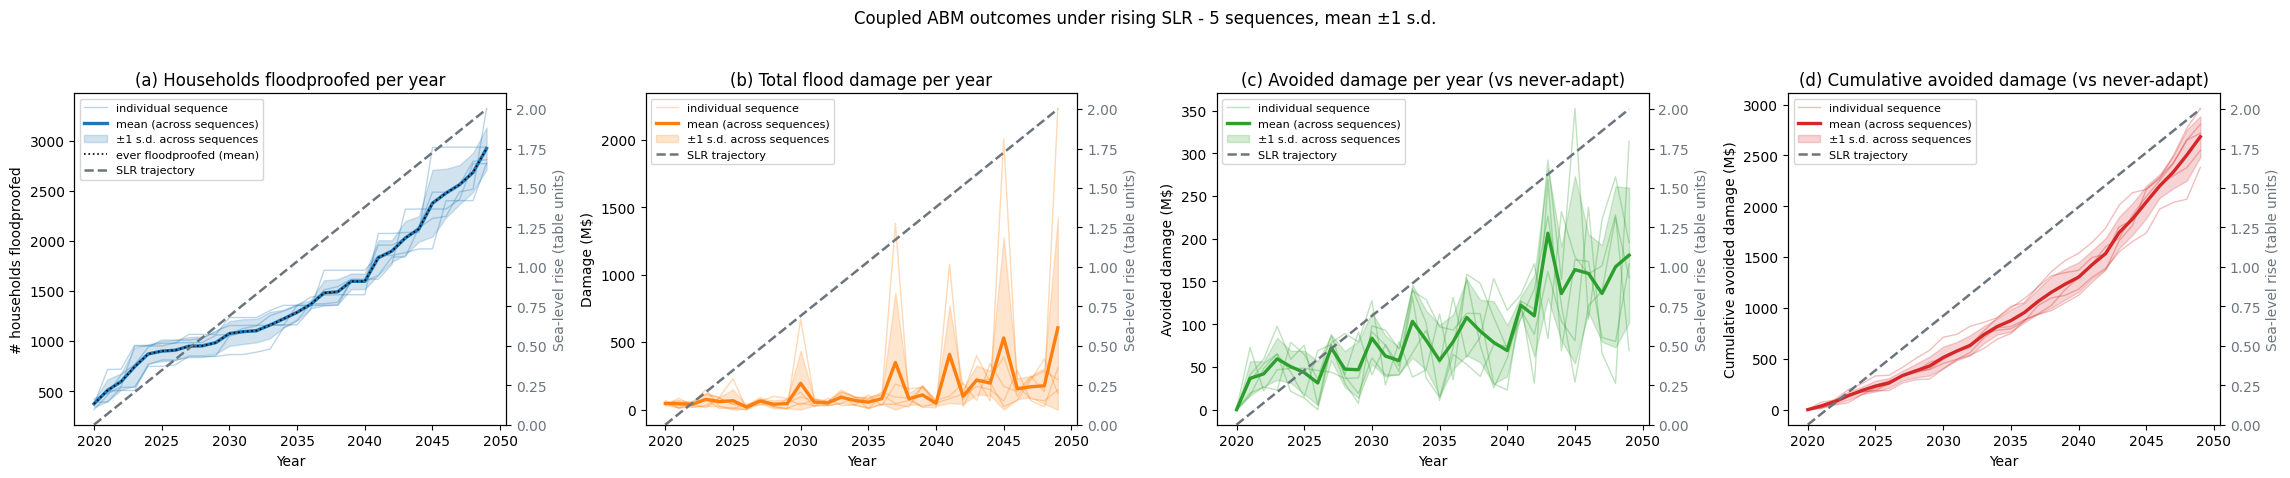

In [20]:
fig = plotting.plot_adaptation_overview(years, slr_values, results, r1_baseline)
plt.show()

### 4.3 A simpler configuration, side by side

A simpler configuration draws events from a clipped Bernoulli trial (capped at 4 per year), treats flood perception as binary, and adapts by a fixed rule: floodproof when this year's damage exceeds 30 % of the maximum potential damage. **R2** runs that combination. Every switch is named explicitly in the cell below; no preset bundles them.

R2 and R1 differ in the hazard draw **and** the decision rule at once, so they are not directly comparable. **R3** closes the gap: the DYNAMO rule on the **same event draws as R2**. Read the three runs as two controlled comparisons:

- **R2 vs R3**: the rule effect, under identical floods.
- **R3 vs R1**: the hazard effect (clip-and-cap vs corrected Poisson), under the same rule.

All three use the same income model, so nothing else varies. Note that an income mode in which income and adaptation cost are both proportional to building value is **not** supported: the affordability gate would reduce to a single constant and never bind for anyone.

#### Same events does not mean same damage curves

The cell asserts that R2 and R3 see **bit-identical flood histories**, and prints `SHARED EVENTS OK` when they do. Their damage curves still differ, and that is the point of the comparison rather than a bug.

The events are the same, but what each event *costs* depends on who has already floodproofed: an adapted household reads the floodproof damage column instead of the no-measures one. R2 and R3 adapt differently, so identical floods produce different realised damage. Only the never-adapt baseline is bit-identical between them, which is exactly what the assertion checks.

The comparison is safe because a decision rule never draws from the hazard random stream. The event draw has its own generator, so swapping the rule cannot shift the flood history.

One thing to watch when reading panel (a), (b) or (c): R1 genuinely **does** have different events, because it uses the Poisson draw. Differences between R1 and the other two mix the rule effect and the hazard effect together.

R3 inherits the clipped hazard's flaws deliberately. It is a control, not a recommended setting.

R3 decision rule : DynamoLiveRule (status: preferred)
[calcEU_do_nothing] Warning, 42838 negative NPVs encountered in floodadapt_abm (0.35%)[calcEU_do_nothing] Warning, 42838 negative NPVs encountered in floodadapt_abm (0.35%)
[calcEU_do_nothing] Warning, 42838 negative NPVs encountered in floodadapt_abm (0.35%)

[calcEU_do_nothing] Warning, 42838 negative NPVs encountered in floodadapt_abm (0.35%)
[calcEU_do_nothing] Warning, 42838 negative NPVs encountered in floodadapt_abm (0.35%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_do_nothing] Warning, 44914 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_do_nothing]

,sequence,final floodproofed (#),final floodproofed (%),ever floodproofed (%),cum. damage (M$),cum. avoided (M$)
0,seq 0,1207.0,2.1,2.1,1810.9,702.3
1,seq 1,1034.0,1.8,1.8,1706.4,985.5
2,seq 2,1485.0,2.6,2.6,2089.5,1276.0
3,seq 3,556.0,1.0,1.0,1351.5,620.5
4,seq 4,1293.0,2.2,2.2,1629.4,599.9
5,MEAN,1115.0,1.9,1.9,1717.5,836.8
6,STD,315.0,0.5,0.5,240.4,259.2


R3 - DYNAMO ABM on the clipped hazard (same events as R2):


,sequence,final floodproofed (#),final floodproofed (%),ever floodproofed (%),cum. damage (M$),cum. avoided (M$)
0,seq 0,2593.0,4.5,4.5,1205.4,1310.4
1,seq 1,2496.0,4.3,4.3,1265.9,1437.5
2,seq 2,2529.0,4.4,4.4,1771.4,1596.4
3,seq 3,2420.0,4.2,4.2,796.5,1182.3
4,seq 4,2599.0,4.5,4.5,962.6,1266.6
5,MEAN,2527.4,4.4,4.4,1200.4,1358.7
6,STD,66.3,0.1,0.1,331.6,144.7


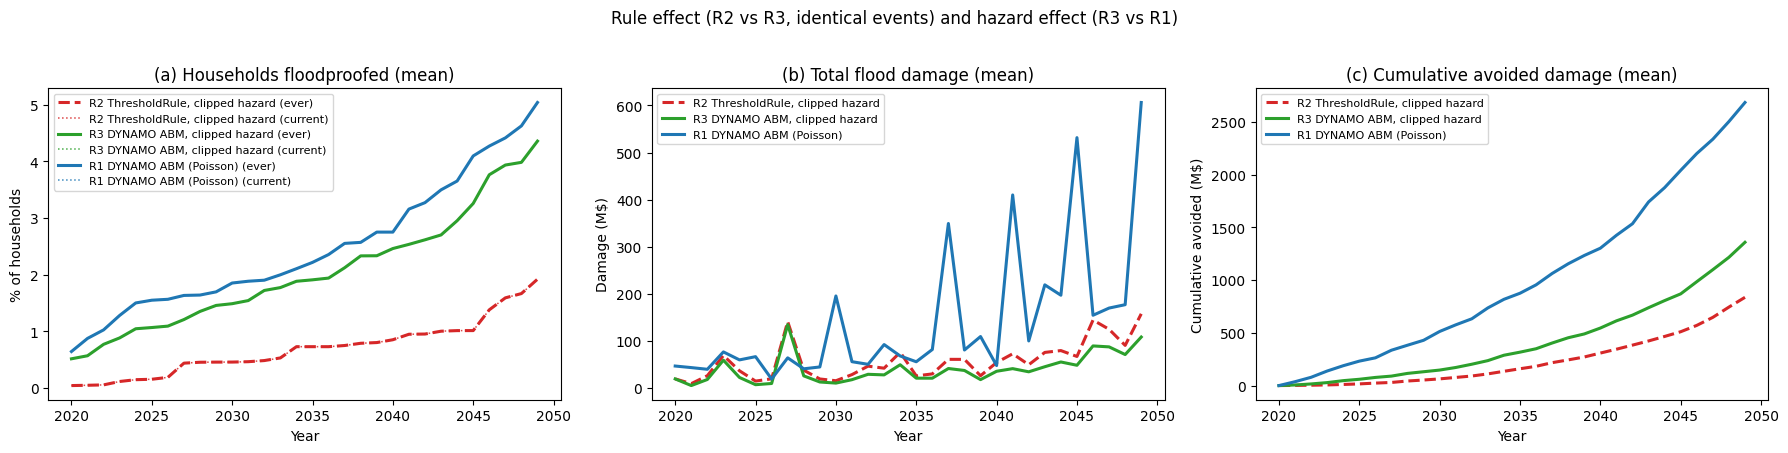

,scenario,final floodproofed (%),ever floodproofed (%),cum. damage (M$),cum. avoided (M$)
0,"R2 ThresholdRule, clipped hazard",1.92,1.92,1717.5,836.8
1,"R3 DYNAMO ABM, clipped hazard",4.36,4.36,1200.4,1358.7
2,R1 DYNAMO ABM (Poisson),5.04,5.04,4250.8,2684.3


In [21]:
# --- R2: ThresholdRule on the clipped hazard draw ----------------------------
# No preset bundles these switches, so each is named explicitly here.
# Income is deliberately held constant across R1, R2 and R3: an income mode
# proportional to max_pot_dmg would make the affordability gate collapse to a
# single global constant that never binds, so all three use the same synthetic
# lognormal income and the comparison isolates the hazard and the rule.
clipped_config = CouplingConfig(
    decision=replace(
        config.decision,
        event_draw_mode="bernoulli_clip",   # clipped Bernoulli draw
        max_events_per_year=4,              # per-year cap
        cap_policy="random",                # uniform discard
        nuisance_freq_threshold=None,       # no nuisance filter
        seu_prob_mode="raw_freq",           # raw frequencies as SEU probabilities
        perception_mode="binary",           # binary perception spike
        flood_significance_threshold=0.0,   # any positive damage counts as a flood
    ),
    random_seed=SEED,
)
clipped_engine = SimulationEngine(
    ds=ds,
    config=clipped_config,
    decision_rule=ThresholdRule(clipped_config.decision, damage_threshold=0.3),
    income_percentile_per_agent=income_percentiles,
)
clipped_res = clipped_engine.run(slr_values, no_seq=NO_SEQ, seed=SEED, n_jobs=-1)
clipped_engine.clear_cache()   # memory hygiene (see Section 4.1)

# --- R2's never-adapt baseline (same clipped event stream) -------------------
clipped_base_config = CouplingConfig(
    decision=replace(clipped_config.decision, lifespan_dryproof=None),
    random_seed=SEED,
)
clipped_base_engine = SimulationEngine(
    ds=ds,
    config=clipped_base_config,
    decision_rule=ThresholdRule(clipped_base_config.decision, damage_threshold=1.01),
    income_percentile_per_agent=income_percentiles,
)
clipped_base = clipped_base_engine.run(slr_values, no_seq=NO_SEQ, seed=SEED, n_jobs=-1)
clipped_base_engine.clear_cache()

# --- R3: DYNAMO ABM on the clipped hazard (same event draws as R2) -----------
matched_config = CouplingConfig(
    decision=replace(
        config.decision,
        event_draw_mode="bernoulli_clip",   # clipped Bernoulli draw
        max_events_per_year=4,              # per-year cap
        cap_policy="random",                # uniform discard
        nuisance_freq_threshold=None,       # no nuisance filter
    ),
    random_seed=SEED,
)
# Preferred rule (native DYNAMO-M when installed; parity-gated port else).
# Parallel-safe: each n_jobs worker clones the rule and gets its own
# native module. The native kernels hold the GIL, so this parallel run is
# correct but effectively serial; we accept that for native fidelity.
matched_rule = preferred_decision_rule(matched_config.decision)
print(f"R3 decision rule : {type(matched_rule).__name__} "
      f"(status: {matched_rule.STATUS})")
matched_engine = SimulationEngine(
    ds=ds,
    config=matched_config,
    decision_rule=matched_rule,
    income_percentile_per_agent=income_percentiles,
)
matched_res = matched_engine.run(slr_values, no_seq=NO_SEQ, seed=SEED, n_jobs=-1)
matched_engine.clear_cache()

# Verify the shared-events premise: a never-adapt run under R3's hazard settings
# must reproduce R2's baseline damages bit-for-bit (damages depend only on events).
matched_base_engine = SimulationEngine(
    ds=ds,
    config=CouplingConfig(
        decision=replace(matched_config.decision, lifespan_dryproof=None),
        random_seed=SEED,
    ),
    decision_rule=ThresholdRule(matched_config.decision, damage_threshold=1.01),
    income_percentile_per_agent=income_percentiles,
)
matched_base = matched_base_engine.run(slr_values, no_seq=NO_SEQ, seed=SEED, n_jobs=-1)
matched_base_engine.clear_cache()
assert np.array_equal(matched_base["damage_history"], clipped_base["damage_history"]), \
    "R2 and R3 do not share the same event draws"
print("SHARED EVENTS OK : R2 and R3 see bit-identical flood histories")

# Same format as Section 4.1; baseline = the clipped never-adapt run for both.
print("\nR2 - ThresholdRule on the clipped hazard:")
display(analysis.create_summary_table(clipped_res, clipped_base))
print("R3 - DYNAMO ABM on the clipped hazard (same events as R2):")
display(analysis.create_summary_table(matched_res, clipped_base))

# Overlay: rule effect (R2 vs R3, identical events) + hazard effect (R3 vs R1).
# Each run is measured against the never-adapt baseline of its own hazard.
runs = {
    "R2 ThresholdRule, clipped hazard": clipped_res,
    "R3 DYNAMO ABM, clipped hazard":    matched_res,
    "R1 DYNAMO ABM (Poisson)":          results,
}
run_baselines = {
    "R2 ThresholdRule, clipped hazard": clipped_base,
    "R3 DYNAMO ABM, clipped hazard":    clipped_base,
    "R1 DYNAMO ABM (Poisson)":          r1_baseline,
}
run_styles = {
    "R2 ThresholdRule, clipped hazard": ("C3", "--"),
    "R3 DYNAMO ABM, clipped hazard":    ("C2", "-"),
    "R1 DYNAMO ABM (Poisson)":          ("C0", "-"),
}
fig = plotting.plot_rule_hazard_comparison(
    years, runs, {k: v["damage_history"] for k, v in run_baselines.items()},
    styles=run_styles,
    title="Rule effect (R2 vs R3, identical events) and hazard effect (R3 vs R1)",
)
plt.show()

# Rule effect (identical event draws, identical income) and hazard effect
# (same rule, clipped draw vs Poisson), one row per run.
display(analysis.scenario_summary(runs, baselines=run_baselines))

# Memory hygiene: keep only R1's results and baseline for the sections below.
del clipped_res, clipped_base, matched_res, matched_base, runs, run_baselines
del clipped_engine, clipped_base_engine, matched_engine, matched_base_engine
gc.collect();

## 5. Insurance experiment: from adapt-or-not to a three-way choice

Two settings:

- **Adaptation only: R1** (Section 3, `include_insurance=False`). Each year a household floodproofs or does nothing.
- **Adaptation plus insurance: R4 and R5** (`include_insurance=True`). The yearly decision becomes three-way: do nothing, floodproof, or insure.

Rules of the game:

- insured households still bear a **10 % deductible**, the share of the damage they keep paying themselves;
- the **6 % expenditure cap** also applies to the premium. An unaffordable premium sets `EU_insure = -inf`, so the household never insures;
- insurance is **annual**, re-decided every year, and never overrides physical floodproofing.

`damage_history` stays gross, before any payout. The run also reports `insured_history`, `out_of_pocket_history`, `premium_history` and `premium_paid_history`.

### 5.1 The two pricing modes, in one table

`insurance_pricing` selects the insurer's rating rule.

| Mode | Premium charged | Effect |
|---|---|---|
| `"community"` (default) | the **mean** expected annual damage of the pool, one flat rate for everybody | low-risk households cross-subsidise high-risk ones |
| `"risk_based"` | each household's **own** expected payout, `(1 - deductible) x EAD_i` | actuarially fair, no cross-subsidy |

**EAD** (expected annual damage) is the damage a household expects in an average year. **Actuarially fair** means priced exactly at expected cost, with no margin.

Where each mode comes from, why risk-based pricing was added beyond native, and how `insurance_loading` and `insurance_subsidy` fit in: [Appendix F](#app-f).

The cell below runs R4 and R5 and compares against R1. Watch two things: how much insurance is taken up, and whether offering insurance changes floodproofing.

Uptake is shown two ways (Section 2.2), in separate panels: the cumulative share that has *ever* insured, and the per-year stock of households *currently* insured. Because insurance is re-decided every year with no carry-over, the stock falls as rising premiums breach the 6 % affordability cap, while floodproofing persists and can only accumulate. The "peak uptake" numbers quoted in Sections 5.2 to 5.4 are peaks of the current stock.


R4 decision rule : DynamoLiveRule (status: preferred; three-way decide)
[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)

[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)

[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_insure] Warning, 26 negative NPVs encountered in floodadapt_abm (0.0%)
[calcEU_i

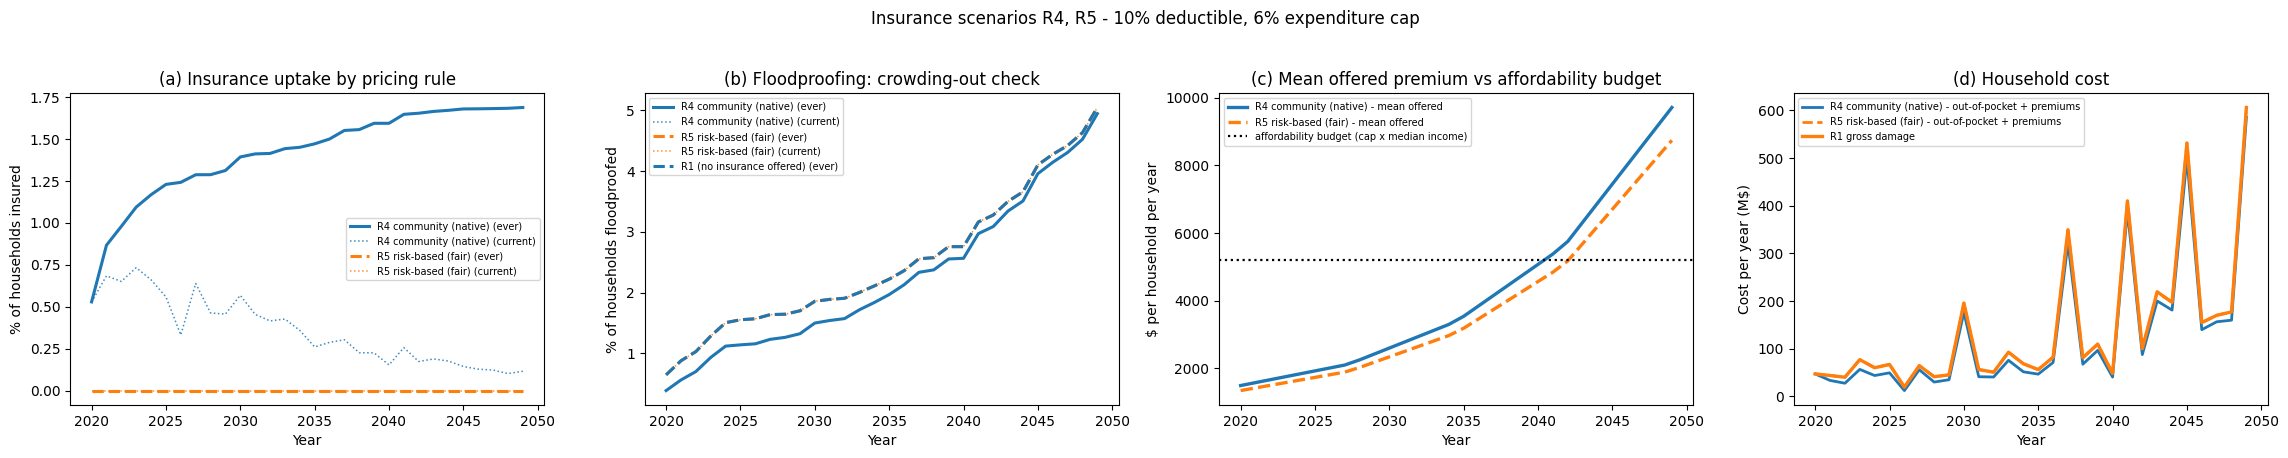

,scenario,final floodproofed (%),ever floodproofed (%),cum. damage (M$),cum. avoided vs reference (M$),peak insured (%),final insured (%),ever insured (%),premium final year ($),cum. household cost (M$)
0,R1 (adaptation only),5.04,5.04,4250.8,0.0,NaN,NaN,NaN,NaN,NaN
1,R4 community (native),4.94,4.94,4769.8,-519.0,0.73,0.12,1.69,9710.0,3806.3
2,R5 risk-based (fair),5.04,5.04,4250.7,0.0,0.00,0.00,0.00,8739.0,4250.7


In [22]:
# R4, R5: insurance scenarios, community vs risk-based pricing,
# compared against R1 (the Section-3 run, no insurance).
# Decision rule per scenario via preferred_decision_rule: R4 (community
# pricing) runs the native DynamoLiveRule; R5 (risk-based) runs the ported
# SEURule, because native calcEU_insure prices one flat premium and cannot
# price per household (see Section 2.8).
# Uses engine.run(n_jobs=-1); DynamoLiveRule.clone() is worker-safe.
def run_insurance(label, pricing, subsidy=0.0, loading=1.0):
    ins_cfg = CouplingConfig(
        decision=replace(
            config.decision,
            include_insurance=True,
            insurance_pricing=pricing,
            insurance_subsidy=subsidy,
            insurance_loading=loading,
        ),
        random_seed=SEED,
    )
    rule = preferred_decision_rule(ins_cfg.decision)
    print(f"{label} decision rule : {type(rule).__name__} "
          f"(status: {rule.STATUS}; three-way decide)")
    eng = SimulationEngine(ds=ds, config=ins_cfg,
                           decision_rule=rule,
                           income_percentile_per_agent=income_percentiles)
    res = eng.run(slr_values, no_seq=NO_SEQ, seed=SEED, n_jobs=-1)
    eng.clear_cache()   # memory hygiene (see Section 4.1)
    return res

scenarios = {
    "R4 community (native)":  run_insurance("R4", "community"),
    "R5 risk-based (fair)":   run_insurance("R5", "risk_based"),
}
# One colour per scenario; line style carries the rating rule (solid
# community, dashed risk-based). The R1 reference is drawn in black.
styles = {"R4 community (native)": ("C0", "-"), "R5 risk-based (fair)": ("C1", "--")}
cap_budget = np.median(engine.income) * config.decision.expenditure_cap

fig = plotting.plot_insurance_overview(
    years, scenarios, reference=results, cap_budget=cap_budget, styles=styles,
    title="Insurance scenarios R4, R5 - 10% deductible, 6% expenditure cap",
)
plt.show()

# One row per run. 'peak/final insured' are the per-year stock (currently
# insured), 'ever insured' the cumulative share; 'cum. avoided vs reference'
# is measured against R1 (negative = more damage than R1).
display(analysis.scenario_summary({"R1 (adaptation only)": results, **scenarios},
                                  reference=results))

# `scenarios` (R4, R5) is kept: the R6-R8 subsidy comparison below reuses it.

### 5.2 Why is uptake so low? The affordability pincer

Both rating rules produce near-zero uptake, but for **opposite reasons**. The cell below diagnoses it at the final sea level by splitting the population by risk.

The risk pool is extremely **skewed**. Mean EAD is about \$9,700 per household, but the median is only \$136 and the 99th percentile is above \$187,000. About 38 % of households have an EAD of \$0, meaning there is nothing to insure. Six percent of the median income is about \$5,000.

- Under **community rating**, the flat premium is the *mean* EAD, roughly \$8,700 by the final year. That is far above what a median-risk household would ever pay for its own tiny risk, and above the 6 % budget of about three quarters of the population. Only the households for whom the flat rate is a bargain, the **cross-subsidised high-risk tail**, have a reason to buy. That is where the small uptake comes from, and it shrinks as the rising flat rate outgrows more and more budgets.
- Under **risk-based rating**, the premium *is* each household's own risk. The median premium collapses to about \$120 and most households (83 %) can afford cover. But affordability and need are inversely sorted. The low-risk majority can pay easily and has nothing worth insuring. Roughly 95 % of the high-risk decile is priced above its 6 % budget and struck out by the affordability constraint (`EU_insure = -inf`). For the small affordable remainder, the expected-utility comparison still favours floodproofing or doing nothing over an annual policy, so uptake stays at zero.

That is the pincer: **the households who would buy cover cannot afford it, and the households who can afford it do not need it.**

The income workflow of Section 2.6 matters here. With real ACS county incomes and the value-proxy pairing of income and risk, more households clear the affordability bar than under a flat \$70k assumption. The pincer's shape is unchanged, but its sharpness depends on the income model. This is exactly why the income inputs are recorded as explicit, replaceable tiers.

,pricing,median premium ($/yr),affordable - all households (%),affordable - top-10% risk (%)
0,community (flat),9710.1,25.5,26.1
1,risk-based,122.1,83.5,4.8


EAD skew         : mean $9,710 | median $136 | p99 $187,331
households with EAD = $0 (nothing to insure): 37.6%
6% budget        : median $5,208


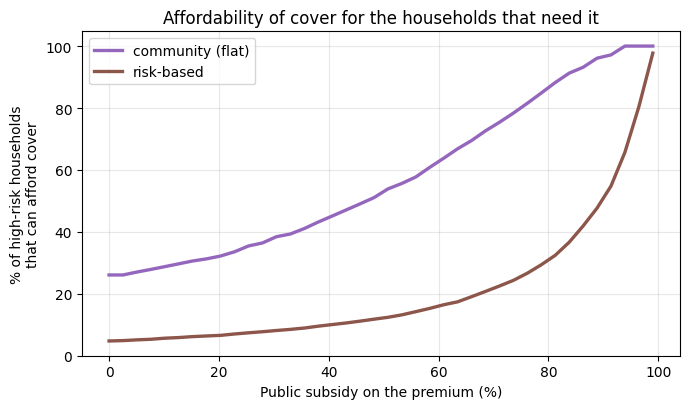

In [23]:
# Diagnostic at the final sea level: who can afford cover, and who needs it?
diag = SimulationEngine(ds=ds, config=config,
                        income_percentile_per_agent=income_percentiles)
diag.prepare_damages(float(slr_values[-1]))
ead    = diag.expected_annual_damages()          # per household, no measures
income = diag.income
cap    = config.decision.expenditure_cap         # 6% of income
deduct = config.decision.insurance_deductible

# Native charges the FULL mean EAD under community rating, even though the
# policy only covers (1 - deductible) of each loss. That is an implicit
# loading of 1/(1 - deductible), about 11 %. analysis.premium_offers mirrors
# the engine exactly; the tail is the top-10%-EAD decile.
display(analysis.affordability_table(ead, income, cap, deduct).round(1))

skew = analysis.ead_summary(ead)
print(f"EAD skew         : mean ${skew['mean']:,.0f} | median ${skew['median']:,.0f} "
      f"| p99 ${skew['p99']:,.0f}")
print(f"households with EAD = $0 (nothing to insure): {100 * skew['share_zero']:.1f}%")
print(f"6% budget        : median ${np.median(income) * cap:,.0f}")

# How deep would a subsidy have to be to make cover reachable for the tail?
subs = np.linspace(0, 0.99, 40)
fig = plotting.plot_affordability_curve(
    subs, analysis.affordability_vs_subsidy(ead, income, cap, deduct, subs))
plt.show()

diag.clear_cache()
del diag

### 5.3 Reading of the insurance results

1. **Voluntary uptake is governed by the expenditure cap, not by the availability of insurance.** In this SEU formulation a household insures only if the premium fits inside 6 % of its income *and* the perceived risk makes cover worth more than doing nothing. For the Charleston pool those two conditions are almost disjoint.
2. **Actuarial fairness alone does not create a market.** Risk-based pricing is the textbook fix for a skewed pool, and it does make cover affordable for the low-risk majority. But it prices most of the high-risk tail out entirely. Community rating is the only rule here that puts *any* households under cover, and it does so purely by cross-subsidy.

   > **Cross-subsidised tail.** Under community rating every household pays the same premium, the pool's *mean* expected annual damage. Households whose own expected damage is below that mean pay more than their own risk is worth. Households above it pay less. That second group is the cross-subsidised tail: high-risk households buying cover at a price set by the average, funded by the low-risk majority. On this table the top-decile household pays roughly a quarter of its own risk. It is the only group for which insuring beats both alternatives, and so the only source of non-zero uptake. Risk-based pricing removes this transfer by construction, which is exactly why its uptake is zero.
3. **Rising sea level erodes the market.** The mean EAD (and hence the flat premium) grows several-fold over the horizon, crossing the affordability cap of more and more households. Uptake therefore decays exactly as the risk becomes most severe. That decay is a property of the *current* stock; the cumulative ever-insured share can only flatten, which is why both are drawn.
4. **Crowding out is invisible in the adoption level, but not absent.** Comparing R4 and R5 against R1, final floodproofing is essentially unchanged (4.7 to 4.8 % in all runs), which looks reassuring. It is not the right statistic. A clean control on this table (R1 against both rules, no subsidy) gives R5 exactly the R1 damage, as it must since nobody insures, but gives R4 **9.1 % more cumulative damage** off a final floodproofing gap of only 0.05 percentage points. The mechanism is **delay, not displacement**: the floodproofing gap is 0.41 percentage points at year five and 0.05 by year thirty, so households insure first and floodproof later. Since the only households for which the flat rate is a bargain are the highest-risk ones, those delayed years are the expensive ones. Judge crowding-out by damage, not by the headline adoption percentage.
5. **The policy lever is the premium-to-income ratio, not the rating rule.** The subsidy curve above shows what fraction of the at-risk tail could *afford* cover at each subsidy level. Affordability is necessary but not sufficient: a household must also prefer insuring to the alternatives. Section 5.4 runs the model at a realistic subsidy level and measures what is actually bought, which is much less than the affordability curve alone suggests. This mirrors the empirical record for voluntary flood insurance.

### 5.4 Does a public subsidy fix it?

Sections 5.2 and 5.3 showed that the binding constraint is the premium-to-income ratio, not the rating rule. The natural next question is a policy one: if the public purse pays part of the bill, does either rule start working?

`insurance_subsidy` is that lever. It is the share of the premium paid by a public scheme rather than the household. The actuarial premium is computed first from each household's expected annual damage, and the subsidy discounts only what the household is asked to pay. The risk signal therefore survives, which is the design the affordability literature recommends: means-tested vouchers paired with risk-based rates, funded from outside the premium pool ([Kousky and Kunreuther 2014](https://www.rff.org/publications/journal-articles/addressing-affordability-in-the-national-flood-insurance-program/); [Zhang, Lin and Kunreuther 2023](https://doi.org/10.1111/risa.14048)).

**Why 60 %.** It is not arbitrary. The pre-reform NFIP ran an implicit subsidy of about this size for decades: pre-FIRM subsidised policies paid on average only 35 to 40 % of the full-risk rate ([GAO-13-607](https://www.gao.gov/products/gao-13-607)). A 60 % subsidy is therefore a real-world anchor rather than a round number. We add a 90 % run for risk-based pricing as well, to find where the threshold actually sits.

**What to watch in the six panels.** One colour per scenario; solid lines are community rating, dashed lines risk-based; R1 is black.

| Panel | Question |
|---|---|
| (a) Ever insured | Does anyone buy once the price falls? The cumulative share can only rise; it flattens when no new household enters. |
| (b) Currently insured | How many hold a policy in a given year? This is where the churn shows: rising premiums push households back out. |
| (c) Floodproofing | Does cheap insurance crowd out physical adaptation? |
| (d) Mean offered premium | How far each policy sits from the 6 % budget line. |
| (e) Cumulative avoided damage | Does the policy reduce total flood losses, or only move who pays? Negative means **more** damage than the no-insurance baseline. |
| (f) Cumulative household cost | Out-of-pocket losses plus premiums paid. This is what households actually bear. |

Panel (e) is the one that matters for a policy read. Insurance does not change the hazard and does not change the building stock. It can only reduce total damage indirectly, by changing how many households floodproof. If a subsidy buys insurance at the expense of floodproofing, avoided damage goes negative.

> **What a single-sequence probe of this configuration found.** A 60 % subsidy moves risk-based uptake **not at all**. The subsidy is proportional, the 6 % cap is absolute: a top-decile household paying about \$46,000 fair still faces \$18,600 after a 60 % discount, against a budget near \$4,200. The same 60 % on the *flat* community rate roughly triples peak uptake, from 0.98 % to 3.06 %, because the flat rate already sits near the cap.

| Rule | Subsidy | Peak uptake | Final floodproofed | Cumulative damage |
|---|---|---|---|---|
| risk-based | 0 % | 0.000 % | 4.70 % | 3,721 M\$ |
| risk-based | 60 % | 0.000 % | 4.70 % | 3,721 M\$ |
| risk-based | 80 % | 0.014 % | 4.70 % | 3,721 M\$ |
| risk-based | 90 % | 1.685 % | 4.49 % | 3,856 M\$ |
| risk-based | 95 % | 5.347 % | 3.37 % | 4,319 M\$ |
| risk-based | 99 % | 11.260 % | 0.99 % | 5,573 M\$ |
| community | 0 % | 0.983 % | 4.65 % | 4,062 M\$ |
| community | 60 % | 3.060 % | 4.06 % | 4,974 M\$ |
| community | 90 % | 7.546 % | 1.07 % | 5,965 M\$ |

Past about 90 % the risk-based subsidy starts to work, and immediately starts to backfire. Community rating shows the same pattern from a higher starting point. Every gain in uptake is paid for in floodproofing, which falls from 4.70 % to 0.99 %, and cumulative flood damage **rises by 50 %**. Insurance transfers losses rather than preventing them, so a subsidy deep enough to make cover attractive also makes it more attractive than protection. A uniform subsidy is the wrong instrument twice over: at realistic depths it helps the households that least need cover, and at the depths that reach the tail it crowds out the measure that actually reduces damage. This is the argument for **means-tested** support sized to each household's affordability gap, paired with mitigation requirements. Run the cell to reproduce this on the full five-sequence setup.


R6 decision rule : DynamoLiveRule (status: preferred; three-way decide)
[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_insure] Warning, 20 negative NPVs encountered in floodadapt_abm (0.0%)
[calcEU_i

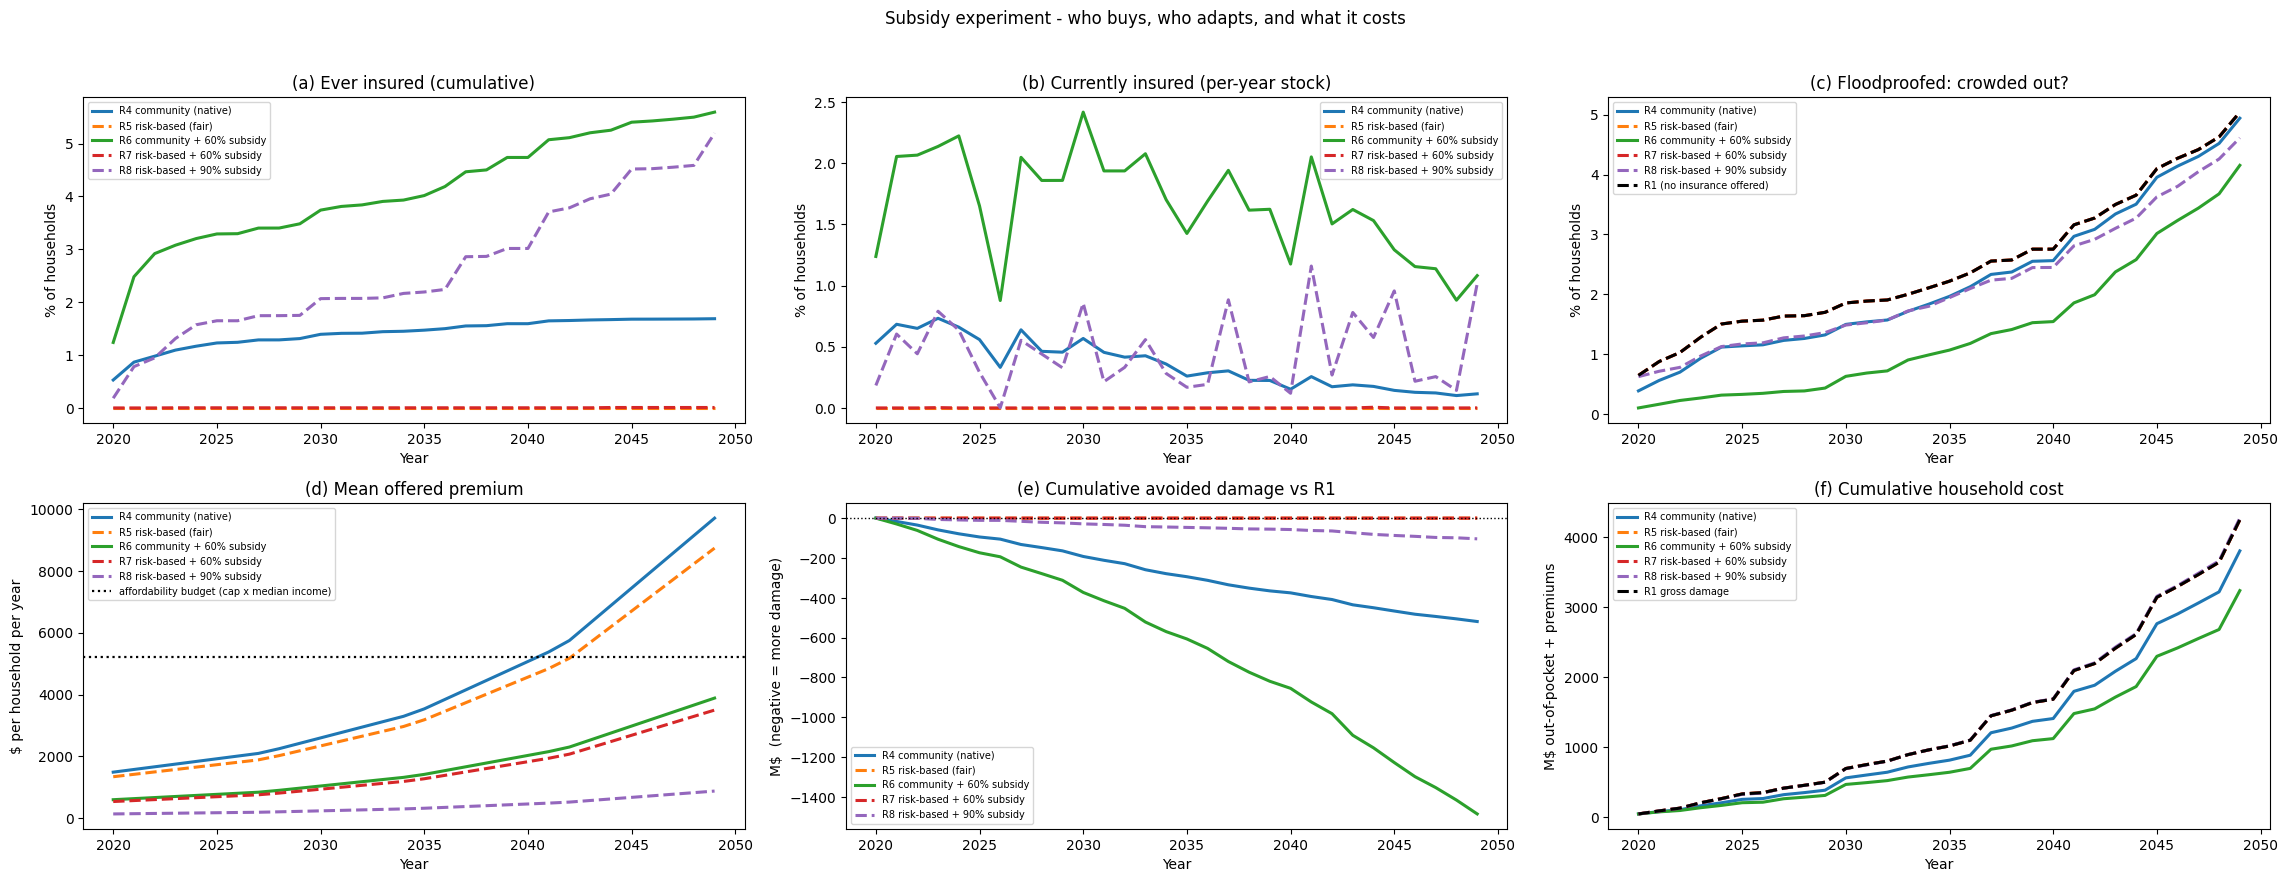

,scenario,final floodproofed (%),ever floodproofed (%),cum. damage (M$),cum. avoided vs reference (M$),peak insured (%),final insured (%),ever insured (%),premium final year ($),cum. household cost (M$)
0,R4 community (native),4.94,4.94,4769.8,-519.0,0.73,0.12,1.69,9710.0,3806.3
1,R5 risk-based (fair),5.04,5.04,4250.7,0.0,0.00,0.00,0.00,8739.0,4250.7
2,R6 community + 60% subsidy,4.15,4.15,5735.7,-1485.0,2.42,1.08,5.59,3884.0,3238.7
3,R7 risk-based + 60% subsidy,5.04,5.04,4250.7,0.0,0.01,0.00,0.01,3496.0,4250.7
4,R8 risk-based + 90% subsidy,4.61,4.61,4354.7,-104.0,1.16,1.02,5.20,874.0,4274.5


In [25]:
# R6, R7, R8: does a public subsidy make either rule work?
# 60% is anchored on the NFIP's own historical implicit subsidy (GAO-13-607:
# pre-FIRM policies paid 35-40% of the full-risk rate). R8 adds a deep 90%
# run for risk-based pricing, to locate the threshold.
import importlib
plotting = importlib.reload(plotting)

SUBSIDY, DEEP = 0.60, 0.90

subsidised = {
    "R6 community + 60% subsidy":   run_insurance("R6", "community",  subsidy=SUBSIDY),
    "R7 risk-based + 60% subsidy":  run_insurance("R7", "risk_based", subsidy=SUBSIDY),
    "R8 risk-based + 90% subsidy":  run_insurance("R8", "risk_based", subsidy=DEEP),
}
all_ins = {**scenarios, **subsidised}
# One colour per scenario; line style carries the rating rule (solid
# community, dashed risk-based). The R1 reference is drawn in black.
style = {
    "R4 community (native)":        ("C0", "-"),
    "R5 risk-based (fair)":         ("C1", "--"),
    "R6 community + 60% subsidy":   ("C2", "-"),
    "R7 risk-based + 60% subsidy":  ("C3", "--"),
    "R8 risk-based + 90% subsidy":  ("C4", "--"),
}

fig = plotting.plot_subsidy_experiment(
    years, all_ins, reference=results, styles=style, reference_label="R1",
    cap_budget=cap_budget,
    title="Subsidy experiment - who buys, who adapts, and what it costs",
)
plt.show()

# 'peak insured' is the per-year stock, 'ever insured' the cumulative share;
# 'cum. avoided vs reference' is measured against R1 (negative = more damage).
display(analysis.scenario_summary(all_ins, reference=results))

# Memory hygiene: free the subsidy payloads. `scenarios` (R4, R5) is kept so
# this cell can be re-run without re-running the R4/R5 cell.
del subsidised, all_ins
gc.collect();

---

# Appendices

The sections above carry the workflow. These appendices carry the background: why a choice was made, where a number came from, and what to read next. Each one is linked from the section it belongs to.

| Appendix | Topic | Linked from |
|---|---|---|
| [A](#app-a) | Parity spot-check, the verification paths | Section 2.3 |
| [B](#app-b) | Scope and design choices | Sections 1.3, 1.4 |
| [C](#app-c) | Household income, in depth | Section 2.6 |
| [D](#app-d) | Decision rules, native versus port | Section 2.8 |
| [E](#app-e) | Reading the `calcEU` warnings | Section 3 |
| [F](#app-f) | Insurance pricing modes | Section 5.1 |


<a id="app-a"></a>

## Appendix A: parity spot-check (verification paths)

The bit-parity contract (`run_mesa_native_full` ≡ `run_mesa_native` ≡ `engine.run(n_jobs=...)`) is enforced continuously by the test suite (`pytest tests/ -q`) and the harnesses in `verification/`. The single cell below is a spot-check that the two verification paths reproduce the Section-3 run (R1) **bit-for-bit** on this very dataset and seed.

In [13]:
# Verification paths on the same engine/seeds as R1 (Section 3).
mirror   = run_mesa_native(engine, slr_values, no_seq=NO_SEQ, seed=SEED, track_eu=True)
parallel = engine.run(slr_values, no_seq=NO_SEQ, seed=SEED, n_jobs=-1)

# Bit-for-bit equality is the coupling's correctness contract.
assert np.array_equal(mirror["damage_history"],  results["damage_history"]),  "mirror != R1"
assert np.array_equal(mirror["adapted_history"], results["adapted_history"]), "mirror != R1"
assert np.array_equal(parallel["damage_history"],  results["damage_history"]),  "parallel != R1"
assert np.array_equal(parallel["adapted_history"], results["adapted_history"]), "parallel != R1"
print("PARITY OK: run_mesa_native == engine.run(n_jobs=-1) == run_mesa_native_full (bit-for-bit)")

# Memory hygiene: drop the verification payloads once the asserts have passed.
del mirror, parallel
gc.collect();

[calcEU_do_nothing] Warning, 42818 negative NPVs encountered in floodadapt_abm (0.37%)
[calcEU_adapt] Warning, 8391 negative NPVs encountered in floodadapt_abm (0.07%)
[calcEU_do_nothing] Warning, 44894 negative NPVs encountered in floodadapt_abm (0.39%)
[calcEU_adapt] Warning, 8873 negative NPVs encountered in floodadapt_abm (0.08%)
[calcEU_do_nothing] Warning, 47200 negative NPVs encountered in floodadapt_abm (0.41%)
[calcEU_adapt] Warning, 10780 negative NPVs encountered in floodadapt_abm (0.09%)
[calcEU_do_nothing] Warning, 50009 negative NPVs encountered in floodadapt_abm (0.43%)
[calcEU_adapt] Warning, 12702 negative NPVs encountered in floodadapt_abm (0.11%)
[calcEU_do_nothing] Warning, 53543 negative NPVs encountered in floodadapt_abm (0.46%)
[calcEU_adapt] Warning, 14361 negative NPVs encountered in floodadapt_abm (0.12%)
[calcEU_do_nothing] Warning, 57572 negative NPVs encountered in floodadapt_abm (0.5%)
[calcEU_adapt] Warning, 15919 negative NPVs encountered in floodadapt_a

---

<a id="app-b"></a>

## Appendix B: Scope and design choices

<a id="app-b1"></a>

### B.1 What the MVP covers, and what it leaves out

The MVP bridges the core SEU decision kernel from DYNAMO-M. It evaluates how agents perceive risk from recent flood events, computes their expected utility for each action, and applies affordability constraints.

The coupling adds, beyond that kernel:

* **flood insurance** as a third decision option (`include_insurance=True`, off by default, matching native);
* a statistically exact **Poisson hazard draw**;
* **severity-scaled risk perception**, a power law with a single shape parameter $\gamma$ (two further one-parameter forms are unsupported after measurement showed they were reparameterisations of $\gamma$);
* a **synthetic income model** ported from native DYNAMO-M;
* an explicit **household income workflow** (Section 2.6 and [Appendix C](#app-c)).

It excludes the broader DYNAMO-M features: the gravity models for migration, regional economic feedbacks, and the government dike cost-benefit agent. Those are reserved for later phases. A feasibility assessment for the government extension is kept with the project deliverables, outside this repository.

<a id="app-b2"></a>

### B.2 Why a lightweight `AgentState`

Spinning up the full DYNAMO-M ecosystem means parsing gigabytes of geospatial data and instantiating a memory-heavy `CoastalNode` object for every building. This engine uses a flat `AgentState` array structure instead. It loads only the property values, damage estimates and event probabilities that the SEU logic actually needs, straight from the NetCDF lookup table.

The result runs in seconds rather than hours. It stays mathematically bit-for-bit identical to native DYNAMO-M, and that identity is enforced by the parity gates in `tests/` and by [Appendix A](#app-a).


---

<a id="app-c"></a>

## Appendix C: Household income, in depth

Background for Section 2.6. Six short parts: the maths, the tiers, the sources, the validation logic, a worked example, and the wealth table.

<a id="app-c1"></a>

### C.1 Why a lognormal, and what the two numbers do

The model assumes regional income follows a **lognormal distribution**: `log(income) ~ Normal(mu, sigma)`. A lognormal has exactly two parameters, `mu` and `sigma`. It is the standard choice for income because it is right-skewed. Most households cluster below the average, and a thin tail of high earners pulls the average up. That skew is exactly what real income data looks like.

Nobody publishes `mu` and `sigma`, though. The census publishes plain statistics, so the code converts.

**Median versus mean.** The **median** is the middle household: half earn more, half earn less. The **mean** is total income divided by the number of households, the plain average. Because a few very rich households pull the average up without moving the middle household, the mean is always at or above the median for a skewed distribution. The gap between them measures the spread.

For a lognormal the conversion is exact:

* `median = exp(mu)`, so `mu = ln(median)`;
* `mean / median = exp(sigma^2 / 2)`, so `sigma = sqrt(2 * ln(mean / median))`.

That second quantity is `mean_median_inc_ratio`. So the pair is not "mean and standard deviation". It is the **median**, which fixes the centre, and the **mean/median ratio**, which fixes the spread. You need both. Two counties can share a median and still be nothing alike, one equal and one very unequal, and only the ratio tells them apart.

**Where this happens in the code.** `_core/dynamo_decision_bridge.py`, in `_synthesize_income_wealth`:

```python
median = float(self._dec.median_income)
mean = median * float(self._dec.mean_median_inc_ratio)
mu = np.log(median)
sd = np.sqrt(2.0 * np.log(mean / median))
distribution = np.sort(rng.lognormal(mu, sd, 5_000).astype(np.int32))
```

**How it is used downstream.** That call builds one sorted 5,000-sample regional income curve per run. Each household then reads its income off that curve at its own income percentile, which comes from step 2 of Section 2.6. Wealth follows from income through the ratio table in [C.6](#app-c6). Income and wealth then feed the affordability check (`expenditure_cap`) inside the adaptation and insurance decision.

The random draw uses a **dedicated generator** seeded from the config seed, so building the income distribution never disturbs the event-draw or decision RNG streams. That is what keeps the bit-parity gates valid.

**Why calibrating this matters.** For Charleston the measured pair is median $88,494 and ratio 1.4879, so `sigma = sqrt(2 * ln(1.4879)) = 0.892`. The package default ratio of 1.15 implies `sigma = 0.529`, a much narrower and, for this county, plainly wrong distribution. See [C.5](#app-c5) for what that does to household incomes.

<a id="app-c2"></a>

### C.2 Step 2, the three tiers, best data first

These tiers grade the **rank assignment** only, which building sits at which percentile. Calibrating the distribution itself ([C.1](#app-c1)) is worth doing at every tier, including the fallback.

**Tier A: real income data joined by location (best).**
Use ACS block-group median household income plus the building footprints. Jargon, defined: **ACS** is the US Census Bureau's American Community Survey. **B19013** is its table "Median Household Income in the Past 12 Months". A **block group** is the smallest census area with published income data, about 600 to 3,000 people. **5-year** means pooled over five survey years, which makes small-area figures reliable. Steps:

1. Get the **income values**. Table B19013 comes from the Census Data API, one row per block group. A free API key is needed. For Charleston County the geography is `state:45 county:019`.
2. Get the **income geometries**. Block-group polygons come from TIGER/Line shapefiles, which need no key. Join them to the values on `GEOID`, the 12-digit block-group identifier. The result is the polygon layer the helper calls `regions_gdf`.
3. Get the **building footprints. This is the hard requirement, and the step that blocks Tier A here.** The lookup `.nc` deliberately carries no coordinates. Its `object_id` axis holds only `max_pot_dmg` and `primary_object_type`. Nothing in the table says where a building is. The geometry has to come from the **FloodAdapt database** that built the table, via `fa.get_building_footprint_impacts(scenario)`. That needs the `[pipeline]` extra and the database itself. Without it there is no way to link a block group to an agent, so steps 1 and 2 alone cannot produce percentiles.
4. **Join and convert.** `income_utils.derive_income_percentiles(...)` does the spatial join and turns each building's block-group income into a percentile. Buildings in richer block groups land on higher percentiles, and a small jitter keeps households in one block group from being identical.
5. Save as `income_percentiles_charleston.npy` next to this notebook. The Tier A/B cell picks the file up automatically.

The helpers `fetch_acs_block_group_income` and `fetch_tract_income` perform steps 1 and 2. They are defined but not called, because step 3 is unavailable here. They do work: against the live API they return 261 Charleston County block groups, 234 of them with a published income (ACS 2020-2024).

**Tier B: coarser open proxies.** If block-group income is unavailable, drop one level to census tracts (99 tracts for Charleston County, 98 with a published income). Outside the US, any polygon layer with an income or GDP-per-capita column works as `regions_gdf`: Global Data Lab subnational areas (`globaldatalab.org`), or a WorldPop wealth grid dissolved to admin units. Nothing else changes, **including the footprint requirement**. Coarser regions carry less contrast between households, so keep the jitter on.

**Tier C: no locations at all. This is what runs here.** There are neither footprints nor a FloodAdapt database on this machine, so a spatial join is impossible. The only per-household covariate in the table is the building value (`max_pot_dmg`). Household income and housing value are correlated, but far from perfectly: rank correlations of roughly 0.4 to 0.6 in household-finance data. `income_utils.percentiles_from_value_proxy` encodes exactly that, with a target rank correlation of 0.5 plus noise.

**This is an assumption, not data.** Unlike the distribution in [C.1](#app-c1), `rho` is not fitted to any Charleston statistic, because there is no per-building income ground truth here to fit it against. It restores plausible sorting of income against risk without repeating the old degenerate identity, income exactly proportional to building value. Treat 0.5 as a calibration target with bounds 0.3 to 0.7 (see `docs/calibration_validation_guide.md`). Passing `None` instead gives the zero-assumption uniform fallback, which is the native default.

<a id="app-c3"></a>

### C.3 Where the ACS numbers come from

**Vintage.** US Census Bureau, American Community Survey, **2020-2024 5-year estimates**, the latest release at the time of writing. Charleston County SC is state FIPS 45, county FIPS 019.

**The three tables used to fit** (see [C.1](#app-c1)):

| Table | What it gives | Value used here |
|---|---|---|
| [B19013](https://data.census.gov/table/ACSDT5Y2024.B19013?g=050XX00US45019) | median household income | $88,494 |
| [B19025](https://data.census.gov/table/ACSDT5Y2024.B19025?g=050XX00US45019) | aggregate household income | $23,566,353,400 |
| [B11001](https://data.census.gov/table/ACSDT5Y2024.B11001?g=050XX00US45019) | number of households | 178,975 |

ACS publishes no mean, so the mean is derived: `B19025 / B11001 = $131,674`. The ratio is then `mean / median = 131,674 / 88,494 = 1.4879`. The [county profile page](https://data.census.gov/profile/Charleston_County,_South_Carolina?g=050XX00US45019) shows the headline figures together.

One machine-readable call returns all three:

```
https://api.census.gov/data/2024/acs/acs5?get=NAME,B19013_001E,B19025_001E,B11001_001E&for=county:019&in=state:45&key=YOUR_KEY
```

**The validation table, B19001, and its 16 brackets.** [B19001](https://data.census.gov/table/ACSDT5Y2024.B19001?g=050XX00US45019) is "Household Income in the Past 12 Months". It counts households in **16 income brackets**.

If a browser view of that table appears to show only a handful of rows, it is showing a collapsed or grouped view, or a different table. The definitive, unambiguous list is the API variable index for the group:

* **[api.census.gov/data/2024/acs/acs5/groups/B19001.html](https://api.census.gov/data/2024/acs/acs5/groups/B19001.html)**

That page lists 17 variables: `B19001_001E` is the **total** number of households, and `B19001_002E` through `B19001_017E` are the **16 brackets**, in order. `fetch_acs_income_brackets` requests exactly those 16 and ignores the total. The bracket edges are pinned in the package as `income_utils.ACS_B19001_EDGES`, and the labels as `ACS_B19001_LABELS`:

`<10k`, `10-15k`, `15-20k`, `20-25k`, `25-30k`, `30-35k`, `35-40k`, `40-45k`, `45-50k`, `50-60k`, `60-75k`, `75-100k`, `100-125k`, `125-150k`, `150-200k`, `200k+`

**Where these numbers actually live.** Each table feeds one thing:

| ACS table | Variables | Fetched by | Ends up in |
|---|---|---|---|
| B19013 | `B19013_001E` | `fetch_acs_county_income` | `median_income` |
| B19025 | `B19025_001E` | same call | numerator of the derived mean |
| B11001 | `B11001_001E` | same call | denominator of the derived mean |
| B19001 | `B19001_002E` to `B19001_017E` | `fetch_acs_income_brackets` | validation only, never stored in the config |

**The package caches nothing.** Both fetchers issue a fresh request on every call. There is no disk cache and no memoisation, so a run without network access cannot fetch. The fitted values live in memory only, on `config.decision.median_income` and `config.decision.mean_median_inc_ratio`. That is exactly why this notebook **pins them as constants**: it reproduces offline, and the live call is used only to report drift.

The only things written to disk are the TIGER/Line shapefiles, cached to `%TEMP%\floodadapt_abm_census` (override with `FA_ABM_CENSUS_CACHE`), and the Tier A/B percentile file `income_percentiles_charleston.npy` if you ever produce one. The API key is read from `CENSUS_API_KEY` and is never written to any file.

**A free API key is required** for every call above, though not for the browser pages or for TIGER/Line shapefiles. Request one at `api.census.gov/data/key_signup.html` and set `CENSUS_API_KEY`. A missing or invalid key is answered with HTTP 200 and an HTML "Missing Key" page rather than an error status, which is why the helpers detect that case and say so plainly.

<a id="app-c4"></a>

### C.4 How calibration and validation are kept apart

**What "calibrated" means here.** There are exactly two free parameters, `median_income` and `mean_median_inc_ratio`. Fitting them is not an optimisation. There is no loss function and nothing is searched. The median is read straight off B19013, which already is a median. The ratio is the derived mean divided by that same median. Two parameters, two independent published numbers, so the fit is exact by construction. `fetch_acs_county_income` does the whole computation in one call.

What that fit cannot tell you is whether a two-parameter lognormal is even the right **shape** for the county. That needs data the fit never touched.

**Why there is no train/test split of rows.** There is no household-level microdata to split. The Census Bureau only ever publishes aggregate tabulations, never individual responses, for privacy. So the held-out material is a **different published table of the same population**, not held-out rows.

The fit uses B19013, B19025 and B11001, three numbers that collapse to two parameters. Validation uses **B19001**, a 16-bracket histogram the fit never sees. Because the fitting numbers summarise far less information than 16 brackets carry, comparing the fitted lognormal's implied bracket shares against the observed ones is a genuine out-of-sample check.

**How it is scored.** `lognormal_bracket_shares` turns the two fitted parameters into the 16 shares the lognormal implies. `bracket_fit_distance` compares them with the observed shares using total-variation distance, which reads directly as the fraction of households the model would place in the wrong bracket. Zero is perfect.

| Parameters | Distance | Reading |
|---|---|---|
| package defaults, $70,000 and 1.15 | 0.326 | about 33 % of households in the wrong bracket |
| ACS-calibrated, $88,494 and 1.4879 | 0.072 | about 7 % in the wrong bracket |

The defaults fail mostly by inventing a thin upper tail where the real county has a fat one: they predict 2.4 % of households above $200k, against 17.2 % observed.

The remaining 7 % sits in the lowest brackets, where a lognormal cannot reproduce the spike of near-zero-income households. That is a limit of the functional form, which is inherited from native DYNAMO-M and cannot be changed without breaking parity. It is recorded rather than tuned away.

<a id="app-c5"></a>

### C.5 Worked example: percentile to income to wealth

Using this notebook's own settings, the Charleston pair ($88,494 and 1.4879) with `SEED = 42`, so `mu = 11.3907` and `sigma = 0.8915`. Reproduce it with the snippet in [C.1](#app-c1) plus the ratio table in [C.6](#app-c6).

| Income percentile | Income | Wealth/income ratio | Wealth |
|---|---|---|---|
| 10 | $28,931 | 0.53 | $15,333 |
| 25 | $48,584 | 1.83 | $88,909 |
| 50 | $86,793 | 4.17 | $361,493 |
| 75 | $162,102 | 4.98 | $806,863 |
| 90 | $273,896 | 5.62 | $1,539,296 |
| 99 | $752,885 | 5.96 | $4,488,700 |

Read one row: a household at the 25th percentile earns $48,584. Its wealth ratio interpolates to 1.83, so its wealth is $88,909. With a 6 % expenditure cap it can commit about $2,915 a year to floodproofing or to a premium. That is the number the affordability check uses.

Two sanity checks on the sampling. The 5,000 draws give a sampled median of $86,793 against the $88,494 that was fitted, and a sampled mean of $132,271 against $131,674. The small gaps are sampling noise plus the integer cast, both inherited from native.

**What the defaults would have given instead**, at the same percentiles:

| Percentile | 10 | 25 | 50 | 75 | 90 | 99 |
|---|---|---|---|---|---|---|
| defaults, $70,000 and 1.15 | $36,070 | $49,052 | $69,198 | $100,228 | $136,800 | $249,180 |
| calibrated, $88,494 and 1.4879 | $28,931 | $48,584 | $86,793 | $162,102 | $273,896 | $752,885 |

The defaults are too narrow at both ends. They make poor households look richer than they are and rich households far poorer. Both errors matter, because affordability is what decides who can act.

<a id="app-c6"></a>

### C.6 The wealth-to-income table

Wealth is not sampled independently. It is derived from income:

```
wealth = ratio(percentile) x income
```

The ratio rises with the income percentile, because richer households hold proportionally more wealth relative to what they earn. The table is six anchor points, linearly interpolated in between:

| Income percentile | 0 | 20 | 40 | 60 | 80 | 100 |
|---|---|---|---|---|---|---|
| Wealth / income | 0.0 | 1.06 | 4.14 | 4.19 | 5.24 | 6.0 |

**Where it comes from, stated honestly.** These are hard-coded constants in native DYNAMO-M (`decision_module.py`, lines 27 to 29), carried over unchanged so the port stays bit-for-bit identical. The native source gives no citation for them beyond the comment "wealth in relation to income".

**For Charleston specifically, this table is not calibrated.** Unlike the income distribution, no local data was used to set it. It is an inherited assumption. If wealth turns out to matter for your conclusions, treat these six numbers as a sensitivity target, and note that changing them breaks parity with native DYNAMO-M.

Keep the contrast in view when writing up. The income marginal is **measured**: two published numbers determine it exactly. The wealth multiplier and the Tier C rank correlation are **assumed**. They should not be reported in the same tone. `docs/calibration_validation_guide.md` lists both under "Inherited constants that are not calibrated", alongside what a real wealth survey would take to fix.


---

<a id="app-d"></a>

## Appendix D: Decision rules, native versus port

Background for Section 2.8.

**The policy: native everywhere it can be.** R1, R3 and R4 all run the native `DynamoLiveRule`, selected by `preferred_decision_rule`. Each cell prints the rule it got. Only two runs do not.

**R2 stays on `ThresholdRule` by design.** It is the simple-baseline arm, so it must not use the SEU science at all.

**R5 must use the port.** Native `calcEU_insure` discounts `premium.mean()`. Its insurer only ever issues one flat community rate, so it cannot express a per-household risk-based premium. Handing it one would silently charge every household the pool average and turn R5 back into R4. The port prices each household individually. This is a capability limit of the native kernel, not a preference. `preferred_decision_rule` applies it automatically, and `DynamoLiveRule.decide` refuses a varying premium rather than averaging it.

**Parallel runs are safe with either rule.** R3 to R5 use `engine.run(n_jobs=-1)`. Each worker clones the rule, and `DynamoLiveRule.clone()` builds a fresh native module per worker, so nothing is shared across threads.

One practical note on speed: the native kernels hold Python's global interpreter lock (**GIL**, the lock that lets only one thread run Python code at a time). A parallel native run is therefore correct but effectively serial. This notebook accepts the longer runtime in exchange for native fidelity. Pass `SEURule` explicitly if throughput matters, since the results are parity-verified identical.

One visible side effect: the native rule prints `[calcEU_*] Warning, N negative NPVs` diagnostics (see [Appendix E](#app-e)), while the port applies the identical maths silently. Those lines appear for R1, R3 and R4, but not for R5.

The alignment of the ported `calcEU_insure` used by R5 is documented in `docs/architecture.md`, Appendix B.


---

<a id="app-e"></a>

## Appendix E: Reading the `calcEU` warnings

Background for the diagnostics printed under the R1 run.

**What they are.** Diagnostic lines printed by the native DYNAMO-M `DecisionModule`. They appear only when `DynamoLiveRule` drives the decisions; the ported `SEURule` applies the identical maths silently. They are not errors, and they do not mean the run is incomplete.

**What they report.** DYNAMO-M evaluates each household's flood risk at a set of points: the household's return periods, for example the 1-in-10-year and the 1-in-100-year event, converted to yearly exceedance probabilities. At each point it computes a net present value of expected damages over the decision horizon, then integrates across points with the trapezoidal rule to get one expected utility number per household.

For some household-and-probability combinations, meaning a specific household at a specific point on its own grid, expected damages are so large that this NPV goes **negative**. The utility function, log or CRRA, is undefined at zero or below. Native floors those entries at 1 before applying it, `NPV = max(1, NPV)`, and the port does exactly the same.

**How to read the numbers.** `N` counts entries of the households by probability-points grid. For the real Charleston table that is about 57,976 households times roughly 200 grid points, so about 11.5 million entries. A figure near 1 % means the floor engaged for the worst probability band of a small share of households.

In this run the share grows with sea level, from 0.4 % to 2.2 % for `calcEU_do_nothing`, and from 0.1 % to 1.1 % for `calcEU_adapt`. It grows because damages grow as the sea rises.

**Why it is harmless here, and what it flags.** Both rules floor identically, bit-for-bit, so parity is unaffected. It is a known calibration point rather than a bug: for the flooring to bind less, incomes, amenity values and damages need a joint calibration pass. See `docs/architecture.md`, Appendix B, and `docs/calibration_validation_guide.md`.


---

<a id="app-f"></a>

## Appendix F: Insurance pricing modes

Background for Section 5.1.

| Mode | Premium charged | Meaning | Origin |
|---|---|---|---|
| `"community"` (default) | the **mean** expected annual damage of the pool, one flat rate for everybody | Low-risk households cross-subsidise high-risk ones. Over a skewed pool the flat rate sits far above the median household's own risk | native DYNAMO-M `InsurerAgent.derive_premium` |
| `"risk_based"` | each household's **own** expected payout, `(1 - deductible) x EAD_i` | The actuarially fair price. It exactly covers the insurer's expected payments for that household, with no cross-subsidy | beyond native |

**Provenance.** *Community rating* is native DYNAMO-M's insurer. It mirrors real community-rated flood schemes, such as the US National Flood Insurance Program (NFIP) before its 2021 reform ([Michel-Kerjan 2010](https://doi.org/10.1257/jep.24.4.165)).

*Risk-based pricing* is the standard actuarial benchmark, premium equals expected loss, and the direction real programs are moving, as in NFIP "Risk Rating 2.0" ([FEMA 2021](https://www.fema.gov/flood-insurance/risk-rating)). It was added beyond native for two reasons:

1. **As a diagnostic**, to test whether the flat community rate is what suppresses uptake. Section 5.2 shows it is not: the expenditure cap binds under either rule.
2. **To make the premium side policy-relevant.** The pricing mode, together with `insurance_loading` (what the insurer adds on top of the expected-loss price, `1.0` means at cost) and `insurance_subsidy` (the public share of the premium), spans the premium designs a public insurer or regulator could actually set.

**What the literature says about the trade-off.** Risk-based premiums reward risk reduction, because lowering your expected damage lowers your premium ([Hudson et al. 2016](https://www.sciencedirect.com/science/article/abs/pii/S0921800916301240); [Kousky 2019](https://doi.org/10.1146/annurev-resource-100518-094028)). But the same link makes them unaffordable exactly in the high-risk tail. Hudson et al. (2016) measure about 20 % of at-risk households in France and Germany unable to afford risk-based premiums. After the NFIP moved to risk-based rates, [Gourevitch, Snyder and Kousky (2025)](https://doi.org/10.63024/32za-vmy3) measured 11 to 39 % fewer new policies, with declines up to 60 % in lower-income zip codes. Community rating avoids that failure but mutes the price signal and overcharges the low-risk majority, which depresses uptake from the other side ([Wagner 2022](https://doi.org/10.1257/pol.20200378)). Our Section 5.2 pincer is the model-side version of exactly this trade-off.

**Where the subsidy fits.** The literature's recommended fix is to keep the risk-based price and pay part of the household's bill from public money, means-tested, rather than distorting premiums inside the pool ([Kousky and Kunreuther 2014](https://www.rff.org/publications/journal-articles/addressing-affordability-in-the-national-flood-insurance-program/); [Zhang, Lin and Kunreuther 2023](https://doi.org/10.1111/risa.14048)). `insurance_subsidy` implements that design: the actuarial premium is computed first, and the subsidy only discounts what the household pays. For scale, the pre-reform NFIP's implicit subsidy was about 0.6 (subsidised policies paid 35 to 40 % of the full-risk rate; [GAO-13-607](https://www.gao.gov/products/gao-13-607)). The 0.9 used in Section 5 is deliberately deeper, chosen to reveal when the high-risk tail finally comes under cover.
